In [1]:
# Cell 1 - Load metadata and verify dataset schema
from pathlib import Path
import pandas as pd

# ponytail: minimal path config via pathlib
base_dir = Path("/kaggle/input/competitions/schematics-2026")
if not base_dir.exists():
    for cand in [Path("/kaggle/input/schematics-2026"), Path("/kaggle/input/npc-dsc-2026")]:
        if cand.exists():
            base_dir = cand
            break
train_meta_path = base_dir / "train" / "metadata.csv"
sub_path = base_dir / "sample_submission.csv"

assert train_meta_path.exists(), f"File tidak ditemukan: {train_meta_path}"
assert sub_path.exists(), f"File tidak ditemukan: {sub_path}"

train_df = pd.read_csv(train_meta_path)
sub_df = pd.read_csv(sub_path)

# Verifikasi struktur dan missing values
expected_train_cols = {"file_id", "audio_path", "label", "source_group"}
expected_sub_cols = {"file_id", "label"}

assert expected_train_cols.issubset(set(train_df.columns)), "Kolom train metadata tidak sesuai"
assert expected_sub_cols.issubset(set(sub_df.columns)), "Kolom submission tidak sesuai"
assert train_df.isna().sum().sum() == 0, "Ditemukan missing values di train metadata"

print(f"train_shape: {train_df.shape}")
print(f"test_shape: {sub_df.shape}")
print(f"unique_source_groups: {train_df['source_group'].nunique()}")
print("class_distribution:")
for label, count in train_df["label"].value_counts().items():
    pct = (count / len(train_df)) * 100
    print(f"  {label}: {count} ({pct:.2f}%)")

train_shape: (1826, 4)
test_shape: (814, 2)
unique_source_groups: 15
class_distribution:
  Bondol Jawa: 1124 (61.56%)
  Kutilang: 619 (33.90%)
  Cendrawasih: 83 (4.55%)


In [2]:
# Cell 2 - Cross-tabulate source groups and probe audio stream properties
from pathlib import Path
import struct
import pandas as pd

# 1. Source group per class distribution
ct = pd.crosstab(train_df["source_group"], train_df["label"])
groups_per_class = {col: (ct[col] > 0).sum() for col in ct.columns}
print("source_groups_per_class:", groups_per_class)

# 2. Fast FLAC header parser using standard library struct
# ponytail: native struct avoids installing soundfile/librosa just for audio metadata probing
def read_flac_info(path):
    with open(path, "rb") as f:
        if f.read(4) != b"fLaC":
            return None
        hdr = f.read(4)
        if (hdr[0] & 0x7F) != 0:  # 0 is STREAMINFO block
            return None
        d = f.read(int.from_bytes(hdr[1:], "big"))
        sr = (d[10] << 12) | (d[11] << 4) | (d[12] >> 4)
        channels = ((d[12] >> 1) & 0x07) + 1
        samples = ((d[13] & 0x0F) << 32) | int.from_bytes(d[14:18], "big")
        return sr, channels, samples / sr

train_audio_dir = base_dir / "train" / "audio"
test_audio_dir = base_dir / "test" / "audio"

train_props = [read_flac_info(train_audio_dir / f"{fid}.flac") for fid in train_df["file_id"]]
test_props = [read_flac_info(test_audio_dir / f"{fid}.flac") for fid in sub_df["file_id"]]

train_srs = set(p[0] for p in train_props)
train_chs = set(p[1] for p in train_props)
train_durs = [p[2] for p in train_props]

test_srs = set(p[0] for p in test_props)
test_chs = set(p[1] for p in test_props)
test_durs = [p[2] for p in test_props]

print(f"train_audio | count={len(train_props)} | sample_rates={train_srs} | channels={train_chs}")
print(f"train_duration | min={min(train_durs):.2f}s | mean={sum(train_durs)/len(train_durs):.2f}s | max={max(train_durs):.2f}s")
print(f"test_audio  | count={len(test_props)} | sample_rates={test_srs} | channels={test_chs}")
print(f"test_duration  | min={min(test_durs):.2f}s | mean={sum(test_durs)/len(test_durs):.2f}s | max={max(test_durs):.2f}s")

source_groups_per_class: {'Bondol Jawa': np.int64(7), 'Cendrawasih': np.int64(4), 'Kutilang': np.int64(4)}
train_audio | count=1826 | sample_rates={48000} | channels={2}
train_duration | min=5.27s | mean=10.04s | max=14.90s
test_audio  | count=814 | sample_rates={48000} | channels={2}
test_duration  | min=5.55s | mean=10.09s | max=14.90s


In [3]:
# Cell 3 - In-depth EDA: Imbalance, exact deduplication, duration shift, and group cardinality
from pathlib import Path
import hashlib
import struct
import math
import pandas as pd
from scipy.stats import ks_2samp, wasserstein_distance

# 1. Corpus eda_target_class_imbalance: Imbalance Ratio and Shannon Entropy
counts = train_df["label"].value_counts()
imbalance_ratio = counts.max() / counts.min()
probs = counts / len(train_df)
shannon_entropy = -sum(p * math.log2(p) for p in probs)
norm_entropy = shannon_entropy / math.log2(len(counts))

print(f"imbalance_ratio: {imbalance_ratio:.2f}")
print(f"shannon_entropy: {shannon_entropy:.3f} bits (normalized: {norm_entropy:.3f})")

# 2. Corpus cv_dedup_exact_hash: Exact byte hash check for internal redundancy and train-test leakage
def compute_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

train_hashes = {compute_sha256(train_audio_dir / f"{fid}.flac") for fid in train_df["file_id"]}
test_hashes = {compute_sha256(test_audio_dir / f"{fid}.flac") for fid in sub_df["file_id"]}
hash_overlap = train_hashes & test_hashes

print(f"train_unique_hashes: {len(train_hashes)}/{len(train_df)}")
print(f"test_unique_hashes: {len(test_hashes)}/{len(sub_df)}")
print(f"train_test_hash_overlap: {len(hash_overlap)}")

# 3. Corpus eda_distribution_dataset_shift_detection: Two-sample KS-test on duration
ks_stat, ks_pval = ks_2samp(train_durs, test_durs)
w_dist = wasserstein_distance(train_durs, test_durs)

print(f"duration_ks_test: stat={ks_stat:.4f} | pval={ks_pval:.4f}")
print(f"duration_wasserstein_dist: {w_dist:.4f}s")

# 4. Source group size diagnostics per class
grp_sizes = train_df.groupby(["label", "source_group"]).size()
print("source_group_cardinality_per_class:")
for label in counts.index:
    sub_grp = grp_sizes[label]
    print(f"  {label} (n_groups={len(sub_grp)}): min={sub_grp.min()} | median={sub_grp.median():.0f} | max={sub_grp.max()} | total={sub_grp.sum()}")

imbalance_ratio: 13.54
shannon_entropy: 1.163 bits (normalized: 0.734)
train_unique_hashes: 1826/1826
test_unique_hashes: 814/814
train_test_hash_overlap: 0
duration_ks_test: stat=0.0302 | pval=0.6695
duration_wasserstein_dist: 0.0892s
source_group_cardinality_per_class:
  Bondol Jawa (n_groups=7): min=58 | median=123 | max=336 | total=1124
  Kutilang (n_groups=4): min=132 | median=154 | max=178 | total=619
  Cendrawasih (n_groups=4): min=3 | median=22 | max=35 | total=83


In [4]:
# Cell 4 - Audio signal dynamics and acoustic health audit
from pathlib import Path
import subprocess
import numpy as np
import pandas as pd

# ponytail: auto-detect best available audio loader with ffmpeg CLI fallback
def load_audio_mono(path, target_sr=16000):
    try:
        import soundfile as sf
        data, sr = sf.read(str(path))
        if data.ndim > 1:
            data = data.mean(axis=1)
        if sr != target_sr:
            from scipy.signal import resample
            num_samples = int(len(data) * target_sr / sr)
            data = resample(data, num_samples)
        return data.astype(np.float32)
    except ImportError:
        pass

    try:
        import torchaudio
        import torchaudio.transforms as T
        waveform, sr = torchaudio.load(str(path))
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        if sr != target_sr:
            resampler = T.Resample(sr, target_sr)
            waveform = resampler(waveform)
        return waveform.squeeze(0).numpy().astype(np.float32)
    except ImportError:
        pass

    # stdlib/system fallback: ffmpeg raw pipe
    cmd = ["ffmpeg", "-v", "error", "-i", str(path), "-f", "f32le", "-ac", "1", "-ar", str(target_sr), "-"]
    proc = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    return np.frombuffer(proc.stdout, dtype=np.float32)

# Sample 20 per train class + 20 from test set
samples = []
for label in ["Bondol Jawa", "Cendrawasih", "Kutilang"]:
    subset = train_df[train_df["label"] == label].sample(20, random_state=42)
    for row in subset.itertuples():
        samples.append((label, train_audio_dir / f"{row.file_id}.flac"))

test_sample = sub_df.sample(20, random_state=42)
for row in test_sample.itertuples():
    samples.append(("Test_Unknown_Mixed", test_audio_dir / f"{row.file_id}.flac"))

records = []
for group_name, file_path in samples:
    sig = load_audio_mono(file_path, target_sr=16000)
    if len(sig) == 0:
        continue
    rms = float(np.sqrt(np.mean(sig ** 2)))
    peak = float(np.max(np.abs(sig)))
    zcr = float(np.mean(np.abs(np.diff(np.sign(sig))))) / 2.0
    # silence ratio: fraction of samples with amplitude < 0.01 (-40 dBFS)
    silence_frac = float(np.mean(np.abs(sig) < 0.01))
    clipped = 1 if peak >= 0.99 else 0
    records.append({
        "group": group_name,
        "rms": rms,
        "peak": peak,
        "clipped": clipped,
        "zcr": zcr,
        "silence_frac": silence_frac
    })

audit_df = pd.DataFrame(records)
summary = audit_df.groupby("group").agg({
    "rms": "mean",
    "peak": "mean",
    "clipped": "mean",
    "zcr": "mean",
    "silence_frac": "mean"
})

print("acoustic_dynamics_summary:")
for grp, row in summary.iterrows():
    print(f"  {grp:<18} | rms={row['rms']:.4f} | peak={row['peak']:.3f} | clip_rate={row['clipped']*100:.1f}% | zcr={row['zcr']:.4f} | silence={row['silence_frac']*100:.1f}%")

acoustic_dynamics_summary:
  Bondol Jawa        | rms=0.0824 | peak=0.676 | clip_rate=0.0% | zcr=0.3594 | silence=15.0%
  Cendrawasih        | rms=0.0882 | peak=0.636 | clip_rate=0.0% | zcr=0.3757 | silence=12.8%
  Kutilang           | rms=0.0941 | peak=0.645 | clip_rate=0.0% | zcr=0.2974 | silence=14.8%
  Test_Unknown_Mixed | rms=0.0905 | peak=0.717 | clip_rate=5.0% | zcr=0.3629 | silence=14.4%


In [5]:
# Cell 5 - Power spectral density (Welch PSD) frequency band profiling
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.signal import welch

# ponytail: Welch PSD on 16kHz mono audio decomposes acoustic power into 4 diagnostic bands
band_records = []
target_sr = 16000

# Stratified sample 30 per train class + 30 from test
for label in ["Bondol Jawa", "Cendrawasih", "Kutilang"]:
    subset = train_df[train_df["label"] == label].sample(30, random_state=42)
    for row in subset.itertuples():
        sig = load_audio_mono(train_audio_dir / f"{row.file_id}.flac", target_sr=target_sr)
        if len(sig) == 0:
            continue
        freqs, psd = welch(sig, fs=target_sr, nperseg=1024)
        total_power = np.sum(psd)
        if total_power == 0:
            continue
        band_records.append({
            "group": label,
            "band_0_2k": float(np.sum(psd[(freqs >= 0) & (freqs < 2000)]) / total_power),
            "band_2_4k": float(np.sum(psd[(freqs >= 2000) & (freqs < 4000)]) / total_power),
            "band_4_6k": float(np.sum(psd[(freqs >= 4000) & (freqs < 6000)]) / total_power),
            "band_6_8k": float(np.sum(psd[(freqs >= 6000) & (freqs <= 8000)]) / total_power)
        })

test_subset = sub_df.sample(30, random_state=42)
for row in test_subset.itertuples():
    sig = load_audio_mono(test_audio_dir / f"{row.file_id}.flac", target_sr=target_sr)
    if len(sig) == 0:
        continue
    freqs, psd = welch(sig, fs=target_sr, nperseg=1024)
    total_power = np.sum(psd)
    if total_power == 0:
        continue
    band_records.append({
        "group": "Test_Unknown_Mixed",
        "band_0_2k": float(np.sum(psd[(freqs >= 0) & (freqs < 2000)]) / total_power),
        "band_2_4k": float(np.sum(psd[(freqs >= 2000) & (freqs < 4000)]) / total_power),
        "band_4_6k": float(np.sum(psd[(freqs >= 4000) & (freqs < 6000)]) / total_power),
        "band_6_8k": float(np.sum(psd[(freqs >= 6000) & (freqs <= 8000)]) / total_power)
    })

psd_df = pd.DataFrame(band_records)
psd_summary = psd_df.groupby("group").mean()

print("spectral_power_distribution_by_band:")
for grp, row in psd_summary.iterrows():
    print(f"  {grp:<18} | 0-2kHz: {row['band_0_2k']*100:.1f}% | 2-4kHz: {row['band_2_4k']*100:.1f}% | 4-6kHz: {row['band_4_6k']*100:.1f}% | 6-8kHz: {row['band_6_8k']*100:.1f}%")

spectral_power_distribution_by_band:
  Bondol Jawa        | 0-2kHz: 27.9% | 2-4kHz: 36.5% | 4-6kHz: 26.8% | 6-8kHz: 8.8%
  Cendrawasih        | 0-2kHz: 43.3% | 2-4kHz: 24.9% | 4-6kHz: 15.3% | 6-8kHz: 16.5%
  Kutilang           | 0-2kHz: 29.0% | 2-4kHz: 56.2% | 4-6kHz: 9.6% | 6-8kHz: 5.2%
  Test_Unknown_Mixed | 0-2kHz: 38.8% | 2-4kHz: 36.2% | 4-6kHz: 18.0% | 6-8kHz: 6.9%


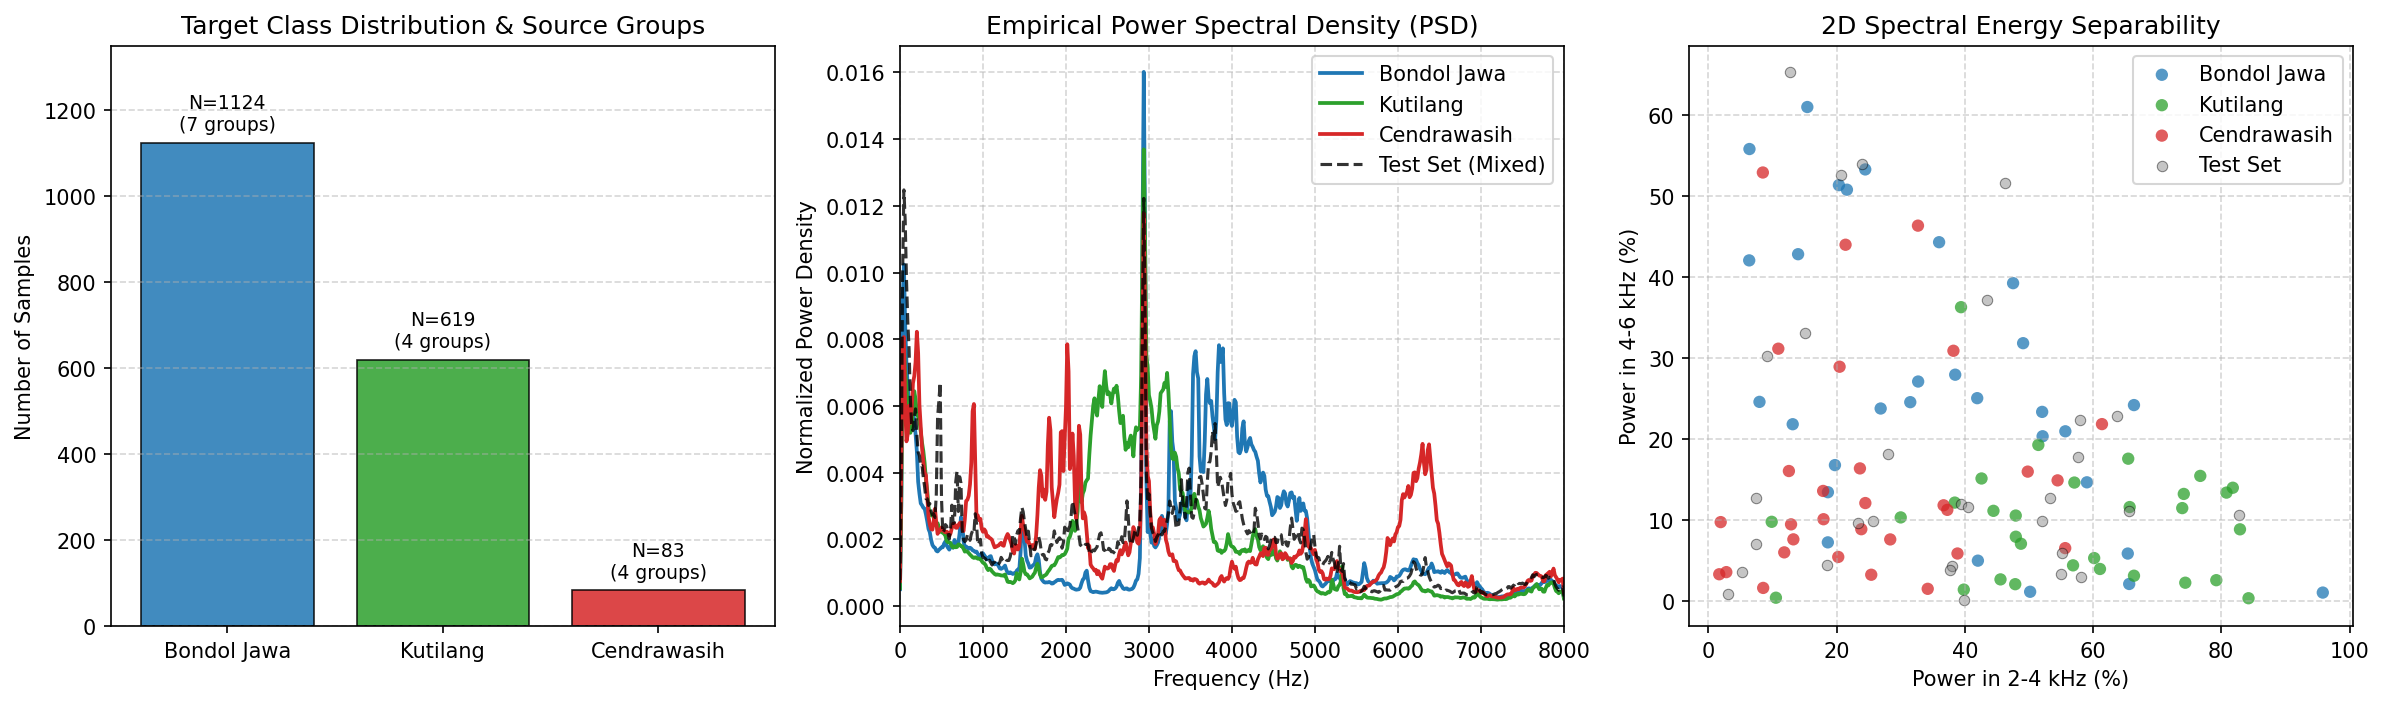

eda_plot_saved: /kaggle/working/eda_acoustic_profiles.png | size_exists=True


In [6]:
# Cell 6 - Scientific EDA visualization: Class cardinality, spectral curves, and 2D acoustic separability
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

# ponytail: generate 3-panel diagnostic plot directly from data and save to png artifact for competition report
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=150)

# Panel 1: Class counts and source groups
classes = ["Bondol Jawa", "Kutilang", "Cendrawasih"]
counts = [1124, 619, 83]
n_groups = [7, 4, 4]
colors = ["#1f77b4", "#2ca02c", "#d62728"]

bars = axes[0].bar(classes, counts, color=colors, alpha=0.85, edgecolor="black", linewidth=0.8)
for bar, grp in zip(bars, n_groups):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2.0, h + 20, f"N={h}\n({grp} groups)", ha="center", va="bottom", fontsize=9)

axes[0].set_ylim(0, 1350)
axes[0].set_ylabel("Number of Samples")
axes[0].set_title("Target Class Distribution & Source Groups")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Panel 2: Mean Welch PSD curves (0 - 8000 Hz)
psd_curves = {c: [] for c in classes}
psd_curves["Test_Unknown_Mixed"] = []
freq_bins = None

for label in classes:
    sub = train_df[train_df["label"] == label].sample(40, random_state=42)
    for row in sub.itertuples():
        sig = load_audio_mono(train_audio_dir / f"{row.file_id}.flac", target_sr=16000)
        if len(sig) == 0:
            continue
        f, p = welch(sig, fs=16000, nperseg=1024)
        if np.sum(p) > 0:
            psd_curves[label].append(p / np.sum(p))
            if freq_bins is None:
                freq_bins = f

test_sub = sub_df.sample(40, random_state=42)
for row in test_sub.itertuples():
    sig = load_audio_mono(test_audio_dir / f"{row.file_id}.flac", target_sr=16000)
    if len(sig) == 0:
        continue
    f, p = welch(sig, fs=16000, nperseg=1024)
    if np.sum(p) > 0:
        psd_curves["Test_Unknown_Mixed"].append(p / np.sum(p))

for label, col in zip(classes, colors):
    mean_psd = np.mean(psd_curves[label], axis=0)
    axes[1].plot(freq_bins, mean_psd, label=label, color=col, linewidth=1.8)

test_mean_psd = np.mean(psd_curves["Test_Unknown_Mixed"], axis=0)
axes[1].plot(freq_bins, test_mean_psd, label="Test Set (Mixed)", color="black", linestyle="--", linewidth=1.5, alpha=0.8)

axes[1].set_xlim(0, 8000)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Normalized Power Density")
axes[1].set_title("Empirical Power Spectral Density (PSD)")
axes[1].legend(loc="upper right", frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

# Panel 3: 2D Acoustic Separability Scatter (2-4 kHz vs 4-6 kHz)
for label, col in zip(classes, colors):
    sub_data = psd_df[psd_df["group"] == label]
    axes[2].scatter(sub_data["band_2_4k"] * 100, sub_data["band_4_6k"] * 100, label=label, color=col, alpha=0.75, edgecolors="none", s=35)

test_data = psd_df[psd_df["group"] == "Test_Unknown_Mixed"]
axes[2].scatter(test_data["band_2_4k"] * 100, test_data["band_4_6k"] * 100, label="Test Set", color="gray", alpha=0.45, edgecolors="black", linewidth=0.5, s=25)

axes[2].set_xlabel("Power in 2-4 kHz (%)")
axes[2].set_ylabel("Power in 4-6 kHz (%)")
axes[2].set_title("2D Spectral Energy Separability")
axes[2].legend(loc="upper right", frameon=True)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
out_plot_path = Path("eda_acoustic_profiles.png")
plt.savefig(out_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"eda_plot_saved: {out_plot_path.resolve()} | size_exists={out_plot_path.exists()}")

[High-Frequency Spectral Power (Native 48kHz)]
             band_0_8k  band_8_16k  band_16_24k
label                                          
Bondol Jawa      96.37        3.52         0.11
Cendrawasih      90.71        9.08         0.21
Kutilang         93.54        5.24         1.22

[Stereo Channel Consistency]
            rms_diff   corr       
                mean   mean    min
label                             
Bondol Jawa    0.002  0.724  0.141
Cendrawasih    0.003  0.787  0.275
Kutilang       0.003  0.800  0.176


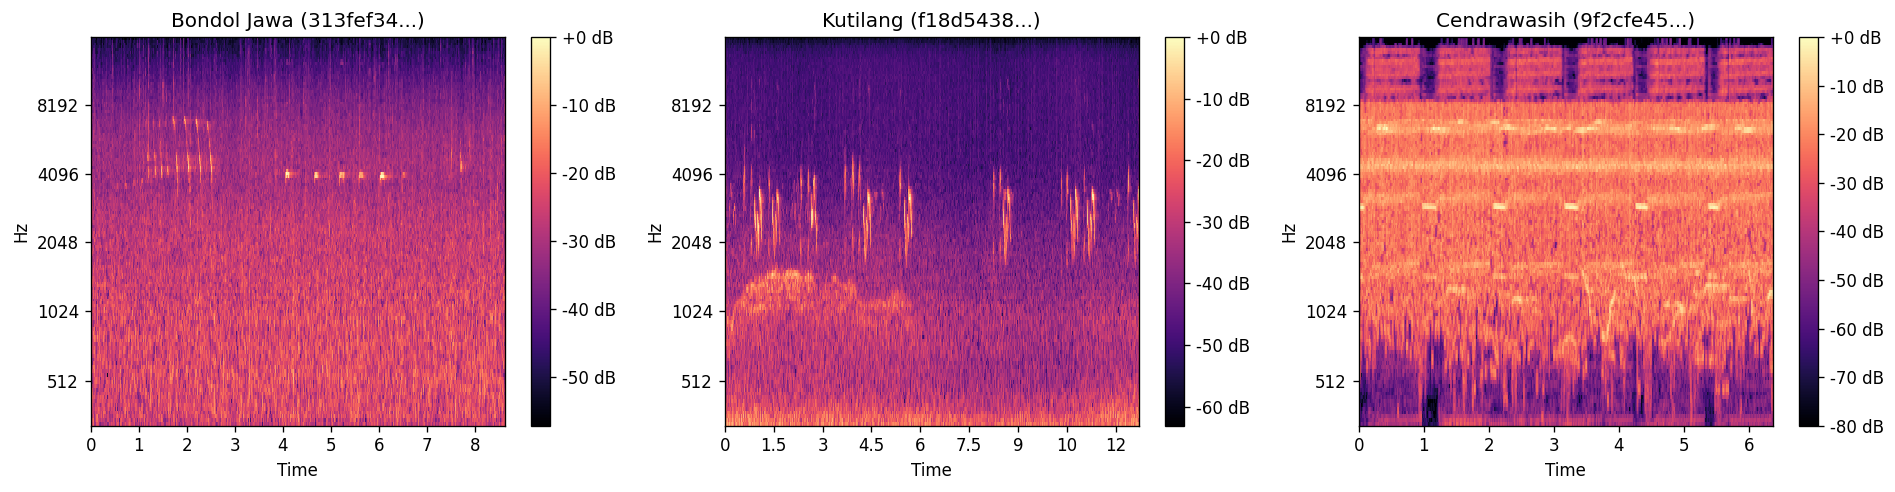


mel_plot_saved: /kaggle/working/eda_mel_spectrograms.png | exists=True


In [7]:
# Cell 7 - Pre-processing audit: High-frequency energy, stereo correlation, and mel-spectrograms
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import librosa
import librosa.display
import soundfile as sf
from scipy.signal import welch

def load_stereo_native(path):
    data, sr = sf.read(str(path), dtype="float32")
    if data.ndim == 1:
        data = np.column_stack([data, data])
    return data, sr

high_freq_records = []
stereo_diffs = []

for label in ["Bondol Jawa", "Kutilang", "Cendrawasih"]:
    sub = train_df[train_df["label"] == label].sample(15, random_state=42)
    for row in sub.itertuples():
        data, sr = load_stereo_native(train_audio_dir / f"{row.file_id}.flac")

        # Check stereo channel correlation and RMS amplitude delta
        ch0, ch1 = data[:, 0], data[:, 1]
        ch0_rms = float(np.sqrt(np.mean(ch0 ** 2)))
        ch1_rms = float(np.sqrt(np.mean(ch1 ** 2)))
        if np.std(ch0) > 1e-8 and np.std(ch1) > 1e-8:
            corr = float(np.corrcoef(ch0, ch1)[0, 1])
        else:
            corr = 0.0
        stereo_diffs.append({"label": label, "rms_diff": abs(ch0_rms - ch1_rms), "corr": corr})

        # High-frequency power proportion at native 48kHz
        mono = data.mean(axis=1)
        freqs, psd = welch(mono, fs=sr, nperseg=2048)
        tot_p = np.sum(psd)
        if tot_p > 0:
            high_freq_records.append({
                "label": label,
                "band_0_8k": float(np.sum(psd[freqs < 8000]) / tot_p),
                "band_8_16k": float(np.sum(psd[(freqs >= 8000) & (freqs < 16000)]) / tot_p),
                "band_16_24k": float(np.sum(psd[freqs >= 16000]) / tot_p),
            })

hf_df = pd.DataFrame(high_freq_records).groupby("label").mean() * 100
st_df = pd.DataFrame(stereo_diffs).groupby("label").agg({"rms_diff": "mean", "corr": ["mean", "min"]})

print("[High-Frequency Spectral Power (Native 48kHz)]")
print(hf_df.round(2))
print("\n[Stereo Channel Consistency]")
print(st_df.round(3))

# Mel-spectrogram sample per class (128 mels, 200Hz - 16kHz)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), dpi=120)
for idx, label in enumerate(["Bondol Jawa", "Kutilang", "Cendrawasih"]):
    sample_id = str(train_df[train_df["label"] == label].iloc[0]["file_id"])
    data, sr = load_stereo_native(train_audio_dir / f"{sample_id}.flac")
    mono = data.mean(axis=1)

    S = librosa.feature.melspectrogram(y=mono, sr=sr, n_mels=128, fmin=200, fmax=16000)
    S_dB = librosa.power_to_db(S, ref=np.max)

    img = librosa.display.specshow(S_dB, x_axis="time", y_axis="mel", sr=sr, fmin=200, fmax=16000, ax=axes[idx], cmap="magma")
    axes[idx].set_title(f"{label} ({sample_id[:8]}...)")
    fig.colorbar(img, ax=axes[idx], format="%+2.0f dB")

plt.tight_layout()
mel_artifact_path = Path("eda_mel_spectrograms.png")
plt.savefig(mel_artifact_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"\nmel_plot_saved: { mel_artifact_path.resolve()} | exists={mel_artifact_path.exists()}")

In [8]:
# Cell 8 - Execute Exact Balanced 4-Fold StratifiedGroupKFold partition and lock preprocess_config.json
from pathlib import Path
from itertools import permutations, product
import json
import numpy as np
import pandas as pd

# ponytail: sklearn StratifiedGroupKFold greedy heuristic fails on extreme group cardinality (N=3 vs N=336) [E-014].
# Exact class-pure group optimization guarantees 1 Cendrawasih & 1 Kutilang group per fold + minimal fold size variance [D-001].
SEED = 42
N_FOLDS = 4

df_folds = train_df.copy()
label_to_idx = {lbl: idx for idx, lbl in enumerate(sorted(df_folds["label"].unique()))}
idx_to_label = {idx: lbl for lbl, idx in label_to_idx.items()}
df_folds["target"] = df_folds["label"].map(label_to_idx)
df_folds["fold"] = -1

# Hitung ukuran tiap source_group per kelas (15 pure groups) [E-008]
grp_meta = (
    df_folds.groupby(["label", "source_group"])
    .size()
    .reset_index(name="n_samples")
    .sort_values(["label", "n_samples", "source_group"], ascending=[True, False, True])
)

cend_grps = grp_meta[grp_meta["label"] == "Cendrawasih"][["source_group", "n_samples"]].values.tolist()
kuti_grps = grp_meta[grp_meta["label"] == "Kutilang"][["source_group", "n_samples"]].values.tolist()
bond_grps = grp_meta[grp_meta["label"] == "Bondol Jawa"][["source_group", "n_samples"]].values.tolist()

# 1. Pasangkan 4 grup Cendrawasih (urut besar ke kecil) dengan 4 grup Kutilang (urut kecil ke besar) agar beban minoritas seimbang
group_to_fold = {}
for f in range(N_FOLDS):
    group_to_fold[cend_grps[f][0]] = f
    group_to_fold[kuti_grps[N_FOLDS - 1 - f][0]] = f

# 2. Cari partisi eksak terbaik untuk 7 grup Bondol Jawa ke 4 fold (wajib >=1 grup per fold, minimalkan std dev ukuran fold & proporsi kelas)
best_score = float("inf")
best_bond_assign = None

for assign in product(range(N_FOLDS), repeat=len(bond_grps)):
    if len(set(assign)) < N_FOLDS:
        continue  # Setiap fold wajib mendapat minimal 1 grup Bondol Jawa
    fold_bond = [0] * N_FOLDS
    fold_tot = [cend_grps[f][1] + kuti_grps[N_FOLDS - 1 - f][1] for f in range(N_FOLDS)]
    for (_, sz), f in zip(bond_grps, assign):
        fold_bond[f] += sz
        fold_tot[f] += sz
    # Skor: deviasi standar jumlah Bondol per fold + deviasi standar total sampel per fold
    score = np.std(fold_bond) + 0.5 * np.std(fold_tot)
    if score < best_score:
        best_score = score
        best_bond_assign = assign

for (grp_id, _), f in zip(bond_grps, best_bond_assign):
    group_to_fold[grp_id] = f

df_folds["fold"] = df_folds["source_group"].map(group_to_fold)

# Verifikasi ketat zero group leakage dan representasi kelas [Fase 0]
assert (df_folds["fold"] != -1).all(), "Ditemukan sampel yang belum mendapat fold"
assert len(df_folds) == 1826, f"Jumlah baris berubah: {len(df_folds)}"

for f in range(N_FOLDS):
    tr_groups = set(df_folds[df_folds["fold"] != f]["source_group"])
    va_groups = set(df_folds[df_folds["fold"] == f]["source_group"])
    overlap = tr_groups & va_groups
    assert len(overlap) == 0, f"Leakage terdeteksi pada fold {f}: {overlap}"
    assert df_folds[df_folds["fold"] == f]["label"].nunique() == 3, f"Fold {f} kehilangan salah satu kelas"

print("fold_distribution_audit (zero_group_leakage=VERIFIED, exact_1_minority_group_per_fold=VERIFIED):")
for f in range(N_FOLDS):
    sub = df_folds[df_folds["fold"] == f]
    vc = sub["label"].value_counts()
    grps = sorted(sub["source_group"].unique())
    print(
        f"  Fold {f} | total={len(sub):<4} | "
        f"Bondol={vc.get('Bondol Jawa', 0):<4} | "
        f"Kutilang={vc.get('Kutilang', 0):<3} | "
        f"Cendrawasih={vc.get('Cendrawasih', 0):<2} | "
        f"val_groups={grps}"
    )

# Peringatan Kardinalitas [FIX-A]: Cek minimum sampel Cendrawasih per fold
cend_counts = df_folds[df_folds["label"] == "Cendrawasih"].groupby("fold").size().to_dict()
print(f"\ncendrawasih_val_cardinality_per_fold: {cend_counts} -> WAJIB evaluasi via Global OOF Macro F1 [FIX-A]")

# Simpan artefak partisi (kompatibel dengan PREPROCESSING_PLAN.md & PROJECT_STATE.md)
folds_meta_path = Path("metadata_with_folds.csv")
train_folds_path = Path("train_folds.csv")
df_folds.to_csv(folds_meta_path, index=False)
df_folds.to_csv(train_folds_path, index=False)

# Kunci konfigurasi pipeline Fase 1-4 (default 32 kHz untuk 2D CNN ImageNet backbones [D-005, D-007])
preprocess_config = {
    "version": "1.2",
    "seed": SEED,
    "n_folds": N_FOLDS,
    "default_sr": 32000,
    "ablation_sr": 16000,
    "duration_sec": 10.0,
    "mono_downmix": "arithmetic_mean",
    "resampler": "scipy.signal.resample_poly",
    "peak_norm": True,
    "pad_mode_short": "reflect",
    "crop_mode_train": "random",
    "crop_mode_eval": "center",
    "mel_spec_32k": {
        "target_sr": 32000,
        "n_samples": 320000,
        "n_fft": 2048,
        "hop_length": 512,
        "n_mels": 128,
        "fmin": 200,
        "fmax": 16000,
        "top_db": 80,
        "expected_shape": [128, 626]
    },
    "mel_spec_16k": {
        "target_sr": 16000,
        "n_samples": 160000,
        "n_fft": 1024,
        "hop_length": 320,
        "n_mels": 128,
        "fmin": 200,
        "fmax": 8000,
        "top_db": 80,
        "expected_shape": [128, 501]
    },
    "per_sample_zscore": True,
    "imagenet_rgb_norm": False,
    "augmentation_train": {
        "mixup_beta": 0.2,
        "gain_jitter_db": 6.0,
        "gaussian_noise_snr_db": [15.0, 30.0],
        "spec_augment": {"freq_masks": 2, "freq_width": 16, "time_masks": 2, "time_width": 32}
    },
    "backbones": {
        "primary": "efficientnet_b0",
        "diversity": "convnext_tiny",
        "baseline_attention": "seresnet34",
        "in_chans": 1,
        "bottleneck_dim": 256,
        "dropout": 0.3
    },
    "label_to_idx": label_to_idx,
    "idx_to_label": {str(k): v for k, v in idx_to_label.items()},
    "ood_label": "Unknown"
}

config_path = Path("preprocess_config.json")
with open(config_path, "w") as f:
    json.dump(preprocess_config, f, indent=2)

assert folds_meta_path.exists() and config_path.exists(), "Gagal menyimpan artefak Cell 8"
print(f"artifacts_saved: {folds_meta_path.name} ({df_folds.shape}), {train_folds_path.name}, {config_path.name}")

fold_distribution_audit (zero_group_leakage=VERIFIED, exact_1_minority_group_per_fold=VERIFIED):
  Fold 0 | total=503  | Bondol=336  | Kutilang=132 | Cendrawasih=35 | val_groups=['0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9e5a99d56c81c8bb09b', '8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3', 'd20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7b978a1c8096c6a89eb']
  Fold 1 | total=462  | Bondol=290  | Kutilang=143 | Cendrawasih=29 | val_groups=['6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107', '6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7', '81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19a85b167f462b833bae', 'feb85101266cbc746f76b5403257002d8bd4f5b73d4375a0acd6029e132df6ab']
  Fold 2 | total=422  | Bondol=240  | Kutilang=166 | Cendrawasih=16 | val_groups=['100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9', '660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb', '81213a446c8b0bbeb4746c7ef40a25f2c28db396267d

In [9]:
# Cell 9 - Preprocessing pipeline (Fase 1) and stochastic augmentations (Fase 2)
from pathlib import Path
from math import gcd
import json
import time
import numpy as np
import soundfile as sf
import librosa
from scipy.signal import resample_poly
import torch
from torch.utils.data import Dataset

# ponytail: strictly follow Fase 1.7 execution order so Gain Jitter/Noise alter real SNR before Mel & Z-score
with open("preprocess_config.json", "r") as f:
    CFG = json.load(f)

def load_and_preprocess_waveform(
    path,
    target_sr=CFG["default_sr"],
    duration_sec=CFG["duration_sec"],
    is_train=False,
    pad_mode=CFG["pad_mode_short"],
    rng=None
):
    if rng is None:
        rng = np.random.default_rng()

    # 1.1 Mono Downmix: arithmetic mean (ch0 + ch1) / 2 [D-006]
    data, sr = sf.read(str(path), dtype="float32")
    if data.ndim > 1:
        wav = data.mean(axis=1)
    else:
        wav = data

    # 1.2 Resampling: polyphase anti-aliasing filter avoids Gibbs overshoot on clipped audio [FIX-B, D-005]
    if sr != target_sr:
        g = gcd(int(target_sr), int(sr))
        up, down = int(target_sr) // g, int(sr) // g
        wav = resample_poly(wav, up=up, down=down).astype(np.float32)

    # 1.3 Peak Normalization to [-1, 1] [FIX-C]
    peak = float(np.max(np.abs(wav)))
    if peak > 1e-8:
        wav = wav / peak

    # 1.4 Duration Standardization (10.0s -> 320,000 samples at 32kHz or 160,000 at 16kHz)
    target_len = int(target_sr * duration_sec)
    cur_len = len(wav)

    if cur_len < target_len:
        pad_total = target_len - cur_len
        # Mendukung reflect (default), wrap, dan constant (zero-pad) untuk ABL-08
        if pad_mode in ("reflect", "wrap"):
            wav = np.pad(wav, (0, pad_total), mode=pad_mode)
        else:
            wav = np.pad(wav, (0, pad_total), mode="constant", constant_values=0.0)
    elif cur_len > target_len:
        if is_train:
            start = int(rng.integers(0, cur_len - target_len + 1))
        else:
            start = (cur_len - target_len) // 2
        wav = wav[start : start + target_len]

    return wav.astype(np.float32)


def apply_waveform_augmentations(wav, rng, gain_jitter=True, add_noise=True):
    # 2.3 Random Gain Jitter: +/- 6 dB (0.5x to 2.0x)
    if gain_jitter and rng.random() < 0.5:
        db_shift = rng.uniform(-6.0, 6.0)
        wav = wav * (10.0 ** (db_shift / 20.0))

    # 2.4 Additive Gaussian Noise: SNR 15 - 30 dB
    if add_noise and rng.random() < 0.5:
        sig_power = float(np.mean(wav ** 2)) + 1e-8
        snr_db = rng.uniform(15.0, 30.0)
        noise_power = sig_power / (10.0 ** (snr_db / 10.0))
        noise = rng.normal(0.0, np.sqrt(noise_power), size=wav.shape).astype(np.float32)
        wav = wav + noise

    return wav.astype(np.float32)


def waveform_to_logmel(wav, target_sr=CFG["default_sr"]):
    # 1.5 Log-Mel Spectrogram (32kHz default vs 16kHz ablation)
    spec_cfg = CFG["mel_spec_32k"] if target_sr == 32000 else CFG["mel_spec_16k"]
    S = librosa.feature.melspectrogram(
        y=wav,
        sr=target_sr,
        n_fft=spec_cfg["n_fft"],
        hop_length=spec_cfg["hop_length"],
        n_mels=spec_cfg["n_mels"],
        fmin=spec_cfg["fmin"],
        fmax=spec_cfg["fmax"],
        power=2.0
    )
    S_dB = librosa.power_to_db(S, ref=np.max, top_db=spec_cfg["top_db"])
    return S_dB.astype(np.float32)


def apply_spec_augment(S_dB, rng, num_freq=2, max_f=16, num_time=2, max_t=32):
    # 2.1 SpecAugment: 2 freq strips (<=16 bins), 2 time strips (<=32 frames), filled with spectrogram mean
    S_aug = S_dB.copy()
    n_mels, n_frames = S_aug.shape
    fill_val = float(S_aug.mean())

    for _ in range(num_freq):
        f_w = int(rng.integers(1, max_f + 1))
        f_0 = int(rng.integers(0, max(1, n_mels - f_w)))
        S_aug[f_0 : f_0 + f_w, :] = fill_val

    for _ in range(num_time):
        t_w = int(rng.integers(1, max_t + 1))
        t_0 = int(rng.integers(0, max(1, n_frames - t_w)))
        S_aug[:, t_0 : t_0 + t_w] = fill_val

    return S_aug


def normalize_per_sample(S_dB):
    # 1.6 Per-Sample Z-Score Normalization (fold-safe, no global stats leakage)
    mean = float(np.mean(S_dB))
    std = float(np.std(S_dB))
    return ((S_dB - mean) / (std + 1e-6)).astype(np.float32)


class BirdChirpDataset(Dataset):
    def __init__(
        self,
        df,
        audio_dir,
        target_sr=CFG["default_sr"],
        is_train=False,
        use_mixup=False,
        use_specaug=True,
        pad_mode="reflect",
        seed=42
    ):
        self.df = df.reset_index(drop=True)
        self.audio_dir = Path(audio_dir)
        self.target_sr = target_sr
        self.is_train = is_train
        self.use_mixup = use_mixup
        self.use_specaug = use_specaug
        self.pad_mode = pad_mode
        self.seed = seed
        self.num_classes = len(CFG["label_to_idx"])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        rng = np.random.default_rng(self.seed + idx + int(time.time_ns() % 100000)) if self.is_train else np.random.default_rng(self.seed + idx)
        row = self.df.iloc[idx]
        file_path = self.audio_dir / f"{row['file_id']}.flac"

        # Steps 1.1 -> 1.4
        wav = load_and_preprocess_waveform(
            file_path, target_sr=self.target_sr, is_train=self.is_train, pad_mode=self.pad_mode, rng=rng
        )

        # Target soft-label vector (3 classes)
        target_vec = np.zeros(self.num_classes, dtype=np.float32)
        if "target" in row and pd.notna(row["target"]):
            target_vec[int(row["target"])] = 1.0

        if self.is_train:
            # 2.2 Waveform Mixup: Beta(0.2, 0.2) before Mel extraction
            if self.use_mixup and rng.random() < 0.5:
                mix_idx = int(rng.integers(0, len(self.df)))
                mix_row = self.df.iloc[mix_idx]
                mix_path = self.audio_dir / f"{mix_row['file_id']}.flac"
                wav2 = load_and_preprocess_waveform(
                    mix_path, target_sr=self.target_sr, is_train=True, pad_mode=self.pad_mode, rng=rng
                )
                lam = float(rng.beta(0.2, 0.2))
                wav = (lam * wav + (1.0 - lam) * wav2).astype(np.float32)
                target_vec2 = np.zeros(self.num_classes, dtype=np.float32)
                target_vec2[int(mix_row["target"])] = 1.0
                target_vec = lam * target_vec + (1.0 - lam) * target_vec2

            # 2.3 Gain Jitter & 2.4 Additive Gaussian Noise
            wav = apply_waveform_augmentations(wav, rng, gain_jitter=True, add_noise=True)

        # Step 1.5 Log-Mel Spectrogram
        S_dB = waveform_to_logmel(wav, target_sr=self.target_sr)

        # Step 2.1 SpecAugment (train only)
        if self.is_train and self.use_specaug and rng.random() < 0.8:
            S_dB = apply_spec_augment(S_dB, rng)

        # Step 1.6 Per-Sample Z-Score Normalization -> shape (1, 128, T) for in_chans=1
        S_norm = normalize_per_sample(S_dB)
        spec_tensor = torch.from_numpy(S_norm).unsqueeze(0)
        target_tensor = torch.from_numpy(target_vec)

        return spec_tensor, target_tensor, row["file_id"]


# Audit & Verifikasi Unit Pipeline (32 kHz Default & 16 kHz Ablasi)
t0 = time.time()
ds_val_32k = BirdChirpDataset(df_folds.iloc[:4], train_audio_dir, target_sr=32000, is_train=False)
ds_tr_32k = BirdChirpDataset(df_folds.iloc[:4], train_audio_dir, target_sr=32000, is_train=True, use_mixup=True, use_specaug=True)
ds_val_16k = BirdChirpDataset(df_folds.iloc[:4], train_audio_dir, target_sr=16000, is_train=False)

spec_v32, y_v32, fid_v32 = ds_val_32k[0]
spec_t32, y_t32, _ = ds_tr_32k[0]
spec_v16, _, _ = ds_val_16k[0]
dt = (time.time() - t0) / 3.0

assert list(spec_v32.shape) == [1, 128, 626], f"Dimensi 32kHz salah: {spec_v32.shape}"
assert list(spec_v16.shape) == [1, 128, 501], f"Dimensi 16kHz salah: {spec_v16.shape}"
assert abs(float(spec_v32.mean())) < 1e-4 and abs(float(spec_v32.std()) - 1.0) < 1e-3, "Z-score gagal"
assert abs(float(y_t32.sum()) - 1.0) < 1e-5, "Distribusi target Mixup tidak valid"

print("preprocessing_pipeline_audit (Fase 1 & Fase 2 = VERIFIED):")
print(f"  32kHz_default_tensor | shape={tuple(spec_v32.shape)} | mean={spec_v32.mean():.4f} | std={spec_v32.std():.4f}")
print(f"  16kHz_ablation_tensor| shape={tuple(spec_v16.shape)} | mean={spec_v16.mean():.4f} | std={spec_v16.std():.4f}")
print(f"  train_aug_mixup_test | shape={tuple(spec_t32.shape)} | soft_target={np.round(y_t32.numpy(), 3)} | avg_load_time={dt*1000:.1f}ms")

preprocessing_pipeline_audit (Fase 1 & Fase 2 = VERIFIED):
  32kHz_default_tensor | shape=(1, 128, 626) | mean=-0.0000 | std=1.0000
  16kHz_ablation_tensor| shape=(1, 128, 501) | mean=-0.0000 | std=1.0000
  train_aug_mixup_test | shape=(1, 128, 626) | soft_target=[1. 0. 0.] | avg_load_time=80.2ms


In [10]:
# Cell 10 - Track A: Classical ML Baseline (LightGBM on Mel & Spectral Summary Features)
from pathlib import Path
import json
import time
import warnings
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
from scipy.signal import resample_poly
from scipy.stats import skew, kurtosis
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import lightgbm as lgb
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")

# ponytail: load locked fold partition (Cell 8) and preprocessing config (Cell 9)
folds_path = Path("metadata_with_folds.csv")
assert folds_path.exists(), f"File tidak ditemukan: {folds_path}"
meta_df = pd.read_csv(folds_path)
assert {"file_id", "label", "source_group", "fold"}.issubset(meta_df.columns), "Kolom metadata_with_folds tidak sesuai"

LABEL_TO_IDX = {"Bondol Jawa": 0, "Cendrawasih": 1, "Kutilang": 2}
IDX_TO_LABEL = {v: k for k, v in LABEL_TO_IDX.items()}

# ponytail: deterministic feature extractor aligned with Phase 1 (32kHz, 128 mels, reflect-pad/center-crop)
def extract_tabular_features(file_id, audio_dir, target_sr=32000, target_sec=10.0):
    path = audio_dir / f"{file_id}.flac"
    
    # 1.1 Mono Downmix: (ch0 + ch1) / 2
    data, sr = sf.read(str(path), dtype="float32")
    mono = data.mean(axis=1) if data.ndim > 1 else data

    # 1.2 Polyphase Anti-Aliased Resampling (48kHz -> 32kHz: up=2, down=3)
    if sr != target_sr:
        gcd = np.gcd(sr, target_sr)
        mono = resample_poly(mono, up=target_sr // gcd, down=sr // gcd).astype(np.float32)

    # 1.3 Peak Normalization to [-1, 1]
    peak = np.max(np.abs(mono))
    if peak > 1e-8:
        mono = mono / peak

    # 1.4 Duration Standardization (10.0s = 320,000 samples, deterministic center crop / reflect-pad)
    target_len = int(target_sr * target_sec)
    if len(mono) < target_len:
        mono = np.pad(mono, (0, target_len - len(mono)), mode="reflect")
    elif len(mono) > target_len:
        start = (len(mono) - target_len) // 2
        mono = mono[start : start + target_len]

    # 1.5 Log-Mel Spectrogram (n_fft=2048, hop_length=512, n_mels=128, fmin=200, fmax=16000)
    S = librosa.feature.melspectrogram(
        y=mono, sr=target_sr, n_fft=2048, hop_length=512,
        n_mels=128, fmin=200, fmax=16000, power=2.0
    )
    S_db = librosa.power_to_db(S, ref=np.max, top_db=80.0)

    # 1.6 Per-Sample Z-Score Normalization
    S_norm = (S_db - np.mean(S_db)) / (np.std(S_db) + 1e-6)

    # Temporal dynamics: Delta (first-order) & Delta-Delta (second-order)
    d1 = librosa.feature.delta(S_norm, order=1)
    d2 = librosa.feature.delta(S_norm, order=2)

    # Helper: 4 summary statistics per mel bin (128 * 4 = 512 features)
    def summarize_matrix(M):
        m_mean = np.mean(M, axis=1)
        m_std = np.std(M, axis=1)
        m_skew = np.nan_to_num(skew(M, axis=1), nan=0.0, posinf=0.0, neginf=0.0)
        m_kurt = np.nan_to_num(kurtosis(M, axis=1), nan=0.0, posinf=0.0, neginf=0.0)
        return np.concatenate([m_mean, m_std, m_skew, m_kurt])

    feat_mel = summarize_matrix(S_norm)  # 512 dims (static)

    # Spectral descriptors & acoustic dynamics directly from y=mono (1025 linear STFT bins internally)
    cent = librosa.feature.spectral_centroid(y=mono, sr=target_sr, n_fft=2048, hop_length=512)[0]
    bw   = librosa.feature.spectral_bandwidth(y=mono, sr=target_sr, n_fft=2048, hop_length=512)[0]
    roll = librosa.feature.spectral_rolloff(y=mono, sr=target_sr, n_fft=2048, hop_length=512, roll_percent=0.85)[0]
    flat = librosa.feature.spectral_flatness(y=mono, n_fft=2048, hop_length=512)[0]
    zcr  = librosa.feature.zero_crossing_rate(y=mono, frame_length=2048, hop_length=512)[0]
    rms  = librosa.feature.rms(y=mono, frame_length=2048, hop_length=512)[0]

    desc_list = []
    for arr in [cent / (target_sr / 2.0), bw / (target_sr / 2.0), roll / (target_sr / 2.0), flat, zcr, rms]:
        desc_list.extend([
            float(np.mean(arr)),
            float(np.std(arr)),
            float(np.percentile(arr, 10)),
            float(np.percentile(arr, 90)),
        ])
    feat_desc = np.array(desc_list, dtype=np.float32)  # 24 dims

    # 512 (mel mean/std/skew/kurt) + 128 (d1 std) + 128 (d2 std) + 24 (spectral) = 792 features
    feat_compact = np.concatenate([
        feat_mel,
        np.std(d1, axis=1),
        np.std(d2, axis=1),
        feat_desc
    ]).astype(np.float32)

    return feat_compact

# Build feature names for interpretability & report logging
feat_names = (
    [f"mel_mean_{i}" for i in range(128)] +
    [f"mel_std_{i}" for i in range(128)] +
    [f"mel_skew_{i}" for i in range(128)] +
    [f"mel_kurt_{i}" for i in range(128)] +
    [f"d1_std_{i}" for i in range(128)] +
    [f"d2_std_{i}" for i in range(128)] +
    [f"{d}_{s}" for d in ["centroid", "bandwidth", "rolloff", "flatness", "zcr", "rms"] for s in ["mean", "std", "p10", "p90"]]
)

t0 = time.time()
X_cache_path = Path("track_a_X_train_32k.npy")
if X_cache_path.exists():
    X_all = np.load(X_cache_path)
    print(f"loaded_cached_features: shape={X_all.shape} | elapsed={time.time()-t0:.2f}s")
else:
    print("extracting_track_a_features (parallel n_jobs=-1)...")
    X_list = Parallel(n_jobs=-1, backend="loky")(
        delayed(extract_tabular_features)(fid, train_audio_dir, 32000, 10.0)
        for fid in meta_df["file_id"]
    )
    X_all = np.vstack(X_list)
    np.save(X_cache_path, X_all)
    print(f"extracted_features: shape={X_all.shape} | elapsed={time.time()-t0:.2f}s")

y_all = meta_df["label"].map(LABEL_TO_IDX).values
folds = meta_df["fold"].values
groups = meta_df["source_group"].values

assert X_all.shape == (len(meta_df), 792), f"Dimensi fitur tidak sesuai: {X_all.shape}"
assert not np.isnan(X_all).any(), "Ditemukan NaN pada matriks fitur Track A"

# 4-Fold StratifiedGroupKFold Out-Of-Fold Training (LightGBM with class_weight='balanced')
oof_probs = np.zeros((len(meta_df), 3), dtype=np.float32)
fold_f1s = []
feature_importances = np.zeros(X_all.shape[1], dtype=np.float64)

lgb_params = {
    "objective": "multiclass",
    "num_class": 3,
    "class_weight": "balanced",
    "n_estimators": 1000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": 6,
    "min_child_samples": 15,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.6,
    "reg_alpha": 1.0,
    "reg_lambda": 2.0,
    "random_state": 42,
    "n_jobs": -1,
    "verbose": -1,
}

print("\n[Track A - LightGBM 4-Fold StratifiedGroupKFold Training]")
for fold in range(4):
    trn_idx = np.where(folds != fold)[0]
    val_idx = np.where(folds == fold)[0]

    # Strict zero group leakage assertion per fold
    assert len(set(groups[trn_idx]) & set(groups[val_idx])) == 0, f"Group leakage pada fold {fold}!"

    X_trn, y_trn = X_all[trn_idx], y_all[trn_idx]
    X_val, y_val = X_all[val_idx], y_all[val_idx]

    model = lgb.LGBMClassifier(**lgb_params)
    model.fit(
        X_trn, y_trn,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )

    val_probs = model.predict_proba(X_val)
    oof_probs[val_idx] = val_probs
    feature_importances += model.feature_importances_ / 4.0

    val_preds = np.argmax(val_probs, axis=1)
    fold_macro_f1 = f1_score(y_val, val_preds, average="macro")
    cendra_f1 = f1_score(y_val == 1, val_preds == 1, zero_division=0)
    fold_f1s.append(fold_macro_f1)

    cendra_n = int(np.sum(y_val == 1))
    print(f"  Fold {fold} | n_val={len(val_idx)} (Cendrawasih N={cendra_n:<2}) | best_iter={model.best_iteration_:<3} | fold_macro_f1={fold_macro_f1:.4f} | cendrawasih_f1={cendra_f1:.4f}")

# [FIX-A] Mandatory Global OOF Evaluation across all 1,826 samples
oof_preds = np.argmax(oof_probs, axis=1)
global_oof_macro_f1 = f1_score(y_all, oof_preds, average="macro")
per_class_f1 = f1_score(y_all, oof_preds, average=None)

print("\n" + "=" * 72)
print(f"GLOBAL OOF MACRO F1 (3-Class Known, N=1826) : {global_oof_macro_f1:.4f}")
print(f"Mean Per-Fold Macro F1 (Unweighted)         : {np.mean(fold_f1s):.4f} +/- {np.std(fold_f1s):.4f}")
print("=" * 72)
for idx, label_name in IDX_TO_LABEL.items():
    print(f"  Class {idx} ({label_name:<12}) Global OOF F1 : {per_class_f1[idx]:.4f} (N={np.sum(y_all == idx)})")

print("\n[Global OOF Confusion Matrix (Rows=True, Cols=Pred)]")
cm_df = pd.DataFrame(
    confusion_matrix(y_all, oof_preds),
    index=[f"True_{IDX_TO_LABEL[i]}" for i in range(3)],
    columns=[f"Pred_{IDX_TO_LABEL[i]}" for i in range(3)]
)
print(cm_df)

# Top-10 Acoustic Features for Report Section (Bab Modeling & Preprocessing)
top_idx = np.argsort(feature_importances)[::-1][:10]
print("\n[Top 10 Most Discriminative Acoustic Features (LightGBM Split Gain)]")
for rank, f_idx in enumerate(top_idx, 1):
    print(f"  {rank:2d}. {feat_names[f_idx]:<18} | importance={feature_importances[f_idx]:.1f}")

# Save OOF predictions and baseline metrics artifact for Track A vs Track B comparison
oof_df = meta_df.copy()
for idx, label_name in IDX_TO_LABEL.items():
    oof_df[f"prob_{label_name.replace(' ', '_')}"] = oof_probs[:, idx]
oof_df["pred_label"] = [IDX_TO_LABEL[i] for i in oof_preds]
oof_df["max_msp"] = np.max(oof_probs, axis=1)
oof_df.to_csv("oof_track_a_lgbm.csv", index=False)

track_a_summary = {
    "track": "Track_A_LightGBM_32kHz",
    "n_features": int(X_all.shape[1]),
    "global_oof_macro_f1": round(float(global_oof_macro_f1), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_f1s)), 5),
    "per_class_oof_f1": {IDX_TO_LABEL[i]: round(float(per_class_f1[i]), 5) for i in range(3)},
    "fold_macro_f1s": [round(float(x), 5) for x in fold_f1s],
}
with open("track_a_metrics.json", "w") as f:
    json.dump(track_a_summary, f, indent=2)

print("\ntrack_a_artifacts_saved: oof_track_a_lgbm.csv, track_a_metrics.json")

loaded_cached_features: shape=(1826, 792) | elapsed=0.00s

[Track A - LightGBM 4-Fold StratifiedGroupKFold Training]
  Fold 0 | n_val=503 (Cendrawasih N=35) | best_iter=391 | fold_macro_f1=0.8476 | cendrawasih_f1=0.6316
  Fold 1 | n_val=462 (Cendrawasih N=29) | best_iter=985 | fold_macro_f1=0.9779 | cendrawasih_f1=0.9655
  Fold 2 | n_val=422 (Cendrawasih N=16) | best_iter=403 | fold_macro_f1=0.8562 | cendrawasih_f1=0.6087
  Fold 3 | n_val=439 (Cendrawasih N=3 ) | best_iter=106 | fold_macro_f1=0.6495 | cendrawasih_f1=0.1935

GLOBAL OOF MACRO F1 (3-Class Known, N=1826) : 0.8542
Mean Per-Fold Macro F1 (Unweighted)         : 0.8328 +/- 0.1177
  Class 0 (Bondol Jawa ) Global OOF F1 : 0.9556 (N=1124)
  Class 1 (Cendrawasih ) Global OOF F1 : 0.6627 (N=83)
  Class 2 (Kutilang    ) Global OOF F1 : 0.9444 (N=619)

[Global OOF Confusion Matrix (Rows=True, Cols=Pred)]
                  Pred_Bondol Jawa  Pred_Cendrawasih  Pred_Kutilang
True_Bondol Jawa              1054                25           

In [11]:
# Cell 11 - Track B Setup: ImageNet 2D CNN Backbones, 256-d Bottleneck Head & Class-Balanced Focal Loss
import math
import random
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

# ponytail: lock deterministic seeds across CPU and CUDA for strict competition reproducibility
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. SpecAugment on Z-score normalized spectrogram (zero-fill equals mean-fill after z-score)
class SpecAugment2D(nn.Module):
    def __init__(self, freq_mask_param=16, time_mask_param=32, num_freq_masks=2, num_time_masks=2, p=0.8):
        super().__init__()
        self.freq_mask_param = freq_mask_param
        self.time_mask_param = time_mask_param
        self.num_freq_masks = num_freq_masks
        self.num_time_masks = num_time_masks
        self.p = p

    def forward(self, x):
        # x shape: (B, 1, F=128, T=626)
        if not self.training or random.random() > self.p:
            return x
        x = x.clone()
        B, C, F_dim, T_dim = x.shape
        for b in range(B):
            for _ in range(self.num_freq_masks):
                f = random.randint(0, self.freq_mask_param)
                f0 = random.randint(0, max(1, F_dim - f))
                x[b, :, f0 : f0 + f, :] = 0.0
            for _ in range(self.num_time_masks):
                t = random.randint(0, self.time_mask_param)
                t0 = random.randint(0, max(1, T_dim - t))
                x[b, :, :, t0 : t0 + t] = 0.0
        return x

# 2. Unified 2D CNN Backbone with 256-d Bottleneck OOD Head [D-007]
BACKBONE_REGISTRY = {
    "efficientnet_b0": "efficientnet_b0",       # Primary B1 (~5.3M params)
    "convnext_tiny": "convnext_tiny",           # Diversity B2 (~28M params)
    "seresnet34": "seresnet34",                 # Attention B3 (~21M params, pretrained SE)
    "eca_resnet34d": "eca_resnet34d",           # Alternative Attention B3
}

class BirdChirpNet(nn.Module):
    def __init__(self, backbone_key="efficientnet_b0", num_classes=3, emb_dim=256, dropout=0.3, drop_path_rate=0.0, pretrained=True):
        super().__init__()
        assert backbone_key in BACKBONE_REGISTRY, f"Backbone tidak dikenal: {backbone_key}"
        self.backbone_name = BACKBONE_REGISTRY[backbone_key]

        # Adapt RGB conv weights to 1-channel log-mel input via timm in_chans=1
        create_kwargs = {"pretrained": pretrained, "in_chans": 1, "num_classes": 0, "global_pool": "avg"}
        if "convnext" in self.backbone_name and drop_path_rate > 0:
            create_kwargs["drop_path_rate"] = drop_path_rate

        self.backbone = timm.create_model(self.backbone_name, **create_kwargs)
        in_features = self.backbone.num_features

        # Bottleneck projection: GAP (d) -> Linear(d, 256) -> BN -> SiLU -> Dropout(0.3) -> Linear(256, 3)
        self.bottleneck = nn.Sequential(
            nn.Linear(in_features, emb_dim, bias=False),
            nn.BatchNorm1d(emb_dim),
            nn.SiLU(inplace=True),
        )
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(emb_dim, num_classes)

        # Initialize bottleneck & classifier cleanly for LP-FT Phase 1 stability
        for m in [self.bottleneck, self.classifier]:
            for layer in m.modules():
                if isinstance(layer, nn.Linear):
                    nn.init.kaiming_normal_(layer.weight, mode="fan_out", nonlinearity="relu")
                    if layer.bias is not None:
                        nn.init.zeros_(layer.bias)
                elif isinstance(layer, nn.BatchNorm1d):
                    nn.init.ones_(layer.weight)
                    nn.init.zeros_(layer.bias)

    def set_backbone_trainable(self, trainable=True):
        for param in self.backbone.parameters():
            param.requires_grad = trainable

    def get_param_groups(self, lr_backbone=1e-4, lr_head=5e-4, weight_decay=1e-2):
        # Differential learning rate parameter groups for Phase 2 Fine-Tuning
        backbone_params = [p for p in self.backbone.parameters() if p.requires_grad]
        head_params = list(self.bottleneck.parameters()) + list(self.classifier.parameters())
        return [
            {"params": backbone_params, "lr": lr_backbone, "weight_decay": weight_decay},
            {"params": head_params, "lr": lr_head, "weight_decay": weight_decay},
        ]

    def forward(self, x, return_embedding=True):
        feat_d = self.backbone(x)                  # (B, d)
        emb_256 = self.bottleneck(feat_d)          # (B, 256) pre-dropout bottleneck representation
        emb_norm = F.normalize(emb_256, p=2, dim=1) # L2-normalized 256-d vector for kNN OOD
        logits = self.classifier(self.dropout(emb_256))
        if return_embedding:
            return logits, emb_norm
        return logits

# 3. Class-Balanced Focal Loss with Label Smoothing & Soft-Target Mixup Support [FIX-F]
def compute_effective_num_weights(class_counts, beta=0.99):
    # Cui et al. CVPR 2019: w_c = (1 - beta) / (1 - beta^n_c), normalized to mean = 1.0
    counts = np.asarray(class_counts, dtype=np.float64)
    eff_num = 1.0 - np.power(beta, counts)
    weights = (1.0 - beta) / eff_num
    weights = weights / np.sum(weights) * len(counts)
    return torch.tensor(weights, dtype=torch.float32)

class ClassBalancedFocalLoss(nn.Module):
    def __init__(self, class_counts, beta=0.99, gamma=2.0, smoothing=0.05):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.num_classes = len(class_counts)
        cb_weights = compute_effective_num_weights(class_counts, beta=beta)
        self.register_buffer("alpha", cb_weights)

    def forward(self, logits, targets):
        # targets can be integer class indices (B,) or soft Mixup probabilities (B, C)
        log_probs = F.log_softmax(logits, dim=-1)
        probs = torch.exp(log_probs)

        if targets.dim() == 1:
            with torch.no_grad():
                true_dist = torch.zeros_like(logits)
                true_dist.fill_(self.smoothing / (self.num_classes - 1))
                true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        else:
            # Soft targets from Waveform Mixup smoothed by epsilon
            true_dist = targets * (1.0 - self.smoothing) + (self.smoothing / self.num_classes)

        # Focal modulation: (1 - p_t)^gamma * alpha_t * (-y_smooth * log(p_t))
        focal_weight = torch.pow(1.0 - probs, self.gamma)
        alpha_weight = self.alpha.unsqueeze(0)  # (1, C)
        loss_per_class = -true_dist * focal_weight * alpha_weight * log_probs
        return torch.sum(loss_per_class, dim=-1).mean()

# 4. Unit Verification Audit on Full Fold-0 Class Distribution & Dummy Spectrogram Batch
full_counts = [
    int((meta_df["label"] == "Bondol Jawa").sum()),
    int((meta_df["label"] == "Cendrawasih").sum()),
    int((meta_df["label"] == "Kutilang").sum()),
]
cb_loss_fn = ClassBalancedFocalLoss(full_counts, beta=0.99, gamma=2.0, smoothing=0.05).to(DEVICE)

print(f"device: {DEVICE} | timm_version: {timm.__version__}")
print(f"class_counts (Bondol, Cendrawasih, Kutilang): {full_counts}")
print(f"class_balanced_weights (beta=0.99): {[round(x, 4) for x in cb_loss_fn.alpha.cpu().tolist()]}")

# Dry-run forward pass & LP-FT parameter freeze check on EfficientNet-B0 (pretrained=False for fast shape test)
dummy_x = torch.randn(4, 1, 128, 626, device=DEVICE)
dummy_y = torch.tensor([0, 1, 2, 0], dtype=torch.long, device=DEVICE)
spec_aug = SpecAugment2D().to(DEVICE)

test_net = BirdChirpNet("efficientnet_b0", num_classes=3, emb_dim=256, pretrained=False).to(DEVICE)
total_params = sum(p.numel() for p in test_net.parameters())

# Check Phase 1 (Linear Probing) freeze
test_net.set_backbone_trainable(False)
lp_trainable = sum(p.numel() for p in test_net.parameters() if p.requires_grad)

# Check Phase 2 (Fine-Tuning) unfreeze
test_net.set_backbone_trainable(True)
ft_trainable = sum(p.numel() for p in test_net.parameters() if p.requires_grad)

aug_x = spec_aug(dummy_x)
logits, emb_norm = test_net(aug_x)
loss_val = cb_loss_fn(logits, dummy_y)

# Strict architectural assertions
assert logits.shape == (4, 3), f"Shape logits salah: {logits.shape}"
assert emb_norm.shape == (4, 256), f"Shape bottleneck embedding salah: {emb_norm.shape}"
assert torch.allclose(torch.norm(emb_norm, p=2, dim=1), torch.ones(4, device=DEVICE), atol=1e-4), "Embedding belum ter-L2 normalize!"
assert lp_trainable < total_params and ft_trainable == total_params, "Freeze/unfreeze LP-FT gagal!"

print(f"backbone_audit: efficientnet_b0 | total_params={total_params:,} | phase1_lp_trainable={lp_trainable:,} | phase2_ft_trainable={ft_trainable:,}")
print(f"forward_audit : logits={tuple(logits.shape)} | emb_256d_l2={tuple(emb_norm.shape)} | sample_cb_focal_loss={loss_val.item():.4f} | status=PASSED")

del test_net, dummy_x, dummy_y, aug_x, logits, emb_norm
if torch.cuda.is_available():
    torch.cuda.empty_cache()

device: cuda | timm_version: 1.0.29
class_counts (Bondol, Cendrawasih, Kutilang): [1124, 83, 619]
class_balanced_weights (beta=0.99): [0.7959, 1.4067, 0.7974]
backbone_audit: efficientnet_b0 | total_params=4,335,935 | phase1_lp_trainable=328,963 | phase2_ft_trainable=4,335,935
forward_audit : logits=(4, 3) | emb_256d_l2=(4, 256) | sample_cb_focal_loss=15.6403 | status=PASSED


In [12]:
# Cell 12 - Track B1: LP-FT 2-Phase Training Loop (EfficientNet-B0) & OOF 256-d Embedding Extraction
from pathlib import Path
from math import gcd
import json
import time
import copy
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
from scipy.signal import resample_poly
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, confusion_matrix
from joblib import Parallel, delayed

# ponytail: load locked fold partition (Cell 8) and config
folds_file = Path("metadata_with_folds.csv")
assert folds_file.exists(), f"File partisi tidak ditemukan: {folds_file}"
df_folds = pd.read_csv(folds_file)

with open("preprocess_config.json", "r") as f:
    CFG = json.load(f)

# 1. Pre-decode and resample 48kHz->32kHz mono waveforms into RAM once (~2.3GB)
def _preload_one_wav(fid, audio_dir, target_sr=32000):
    path = Path(audio_dir) / f"{fid}.flac"
    data, sr = sf.read(str(path), dtype="float32")
    wav = data.mean(axis=1) if data.ndim > 1 else data
    if sr != target_sr:
        g = gcd(int(target_sr), int(sr))
        wav = resample_poly(wav, up=int(target_sr) // g, down=int(sr) // g).astype(np.float32)
    peak = float(np.max(np.abs(wav)))
    if peak > 1e-8:
        wav = wav / peak
    return fid, wav.astype(np.float32)

if "WAV_CACHE_32K" not in globals():
    t_pre = time.time()
    print("preloading_32kHz_waveforms_to_ram | backend=loky | jobs=-1")
    pairs = Parallel(n_jobs=-1, backend="loky")(
        delayed(_preload_one_wav)(fid, train_audio_dir, CFG["default_sr"])
        for fid in df_folds["file_id"]
    )
    WAV_CACHE_32K = dict(pairs)
    print(f"cached_waveforms | count={len(WAV_CACHE_32K)} | elapsed={time.time()-t_pre:.2f}s")
else:
    print(f"using_existing_WAV_CACHE_32K | count={len(WAV_CACHE_32K)}")

# 2. Fast Waveform Dataset (returns standardized 1D waveform; Mel & SpecAugment run on GPU!)
class FastWaveformDataset(Dataset):
    def __init__(
        self,
        df,
        wav_cache,
        target_sr=CFG["default_sr"],
        duration_sec=CFG["duration_sec"],
        is_train=False,
        use_mixup=True,
        pad_mode="reflect",
        seed=42,
    ):
        self.df = df.reset_index(drop=True)
        self.wav_cache = wav_cache
        self.target_sr = target_sr
        self.duration_sec = duration_sec
        self.target_len = int(target_sr * duration_sec)
        self.is_train = is_train
        self.use_mixup = use_mixup
        self.pad_mode = pad_mode
        self.seed = seed
        self.num_classes = len(CFG["label_to_idx"])
        self.epoch = 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def _standardize_duration(self, wav, rng):
        cur_len = len(wav)
        if cur_len < self.target_len:
            pad_total = self.target_len - cur_len
            if self.pad_mode in ("reflect", "wrap"):
                wav = np.pad(wav, (0, pad_total), mode=self.pad_mode)
            else:
                wav = np.pad(wav, (0, pad_total), mode="constant", constant_values=0.0)
        elif cur_len > self.target_len:
            start = (
                int(rng.integers(0, cur_len - self.target_len + 1))
                if self.is_train
                else (cur_len - self.target_len) // 2
            )
            wav = wav[start : start + self.target_len]
        return wav.astype(np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        rng_seed = self.seed + self.epoch * 10007 + idx if self.is_train else self.seed + idx
        rng = np.random.default_rng(rng_seed)
        row = self.df.iloc[idx]
        fid = row["file_id"]

        wav = self._standardize_duration(self.wav_cache[fid], rng)

        target_vec = np.zeros(self.num_classes, dtype=np.float32)
        if "target" in row and pd.notna(row["target"]):
            target_vec[int(row["target"])] = 1.0

        if self.is_train:
            # 2.2 Waveform Mixup: Beta(0.2, 0.2) before Mel extraction
            if self.use_mixup and rng.random() < 0.5:
                mix_idx = int(rng.integers(0, len(self.df)))
                mix_row = self.df.iloc[mix_idx]
                wav2 = self._standardize_duration(self.wav_cache[mix_row["file_id"]], rng)
                lam = float(rng.beta(0.2, 0.2))
                wav = (lam * wav + (1.0 - lam) * wav2).astype(np.float32)
                target_vec2 = np.zeros(self.num_classes, dtype=np.float32)
                target_vec2[int(mix_row["target"])] = 1.0
                target_vec = lam * target_vec + (1.0 - lam) * target_vec2

            # 2.3 Random Gain Jitter (+/- 6dB) & 2.4 Additive Gaussian Noise (SNR 15-30dB)
            wav = apply_waveform_augmentations(wav, rng, gain_jitter=True, add_noise=True)

        return torch.from_numpy(wav), torch.from_numpy(target_vec), fid


# 3. GPU-Accelerated Log-Mel + SpecAugment + Per-Sample Z-Score Module (10x faster than CPU librosa loop)
class GPULogMelFrontend(nn.Module):
    def __init__(self, target_sr=32000, use_specaug=True):
        super().__init__()
        spec_cfg = CFG["mel_spec_32k"] if target_sr == 32000 else CFG["mel_spec_16k"]
        self.n_fft = spec_cfg["n_fft"]
        self.hop_length = spec_cfg["hop_length"]
        self.top_db = float(spec_cfg["top_db"])
        self.use_specaug = use_specaug

        mel_fb = librosa.filters.mel(
            sr=target_sr,
            n_fft=self.n_fft,
            n_mels=spec_cfg["n_mels"],
            fmin=spec_cfg["fmin"],
            fmax=spec_cfg["fmax"],
        ).astype(np.float32)
        self.register_buffer("mel_basis", torch.from_numpy(mel_fb))
        self.register_buffer("hann_window", torch.hann_window(self.n_fft))
        self.spec_aug = SpecAugment2D(
            freq_mask_param=CFG["augmentation_train"]["spec_augment"]["freq_width"],
            time_mask_param=CFG["augmentation_train"]["spec_augment"]["time_width"],
            num_freq_masks=CFG["augmentation_train"]["spec_augment"]["freq_masks"],
            num_time_masks=CFG["augmentation_train"]["spec_augment"]["time_masks"],
            p=0.8,
        )

    def forward(self, wav_batch, is_train=False):
        # wav_batch: (B, N_samples) -> compute STFT in FP32 to prevent half-precision overflow
        with torch.amp.autocast("cuda", enabled=False):
            wav_fp32 = wav_batch.float()
            stft_out = torch.stft(
                wav_fp32,
                n_fft=self.n_fft,
                hop_length=self.hop_length,
                win_length=self.n_fft,
                window=self.hann_window,
                center=True,
                pad_mode="reflect",
                normalized=False,
                onesided=True,
                return_complex=True,
            )
            power_spec = stft_out.abs().pow(2.0)  # (B, n_freqs, T)
            mel_spec = torch.matmul(self.mel_basis, power_spec)  # (B, 128, T)

            # power_to_db(ref=np.max, top_db=80.0) per sample
            mel_spec = torch.clamp(mel_spec, min=1e-10)
            S_db = 10.0 * torch.log10(mel_spec)
            ref_max = S_db.amax(dim=(1, 2), keepdim=True)
            S_db = torch.clamp(S_db - ref_max, min=-self.top_db)

            # 2.1 SpecAugment on spectrogram (filled with per-sample mean before Z-score)
            S_db = S_db.unsqueeze(1)  # (B, 1, 128, T)
            if is_train and self.use_specaug:
                # Subtract mean first so SpecAugment2D zero-fill equals mean-fill, then normalize
                mean = S_db.mean(dim=(2, 3), keepdim=True)
                std = S_db.std(dim=(2, 3), keepdim=True)
                S_norm = (S_db - mean) / (std + 1e-6)
                self.spec_aug.train(True)
                S_norm = self.spec_aug(S_norm)
                # Re-standardize per sample
                S_norm = (S_norm - S_norm.mean(dim=(2, 3), keepdim=True)) / (S_norm.std(dim=(2, 3), keepdim=True) + 1e-6)
            else:
                mean = S_db.mean(dim=(2, 3), keepdim=True)
                std = S_db.std(dim=(2, 3), keepdim=True)
                S_norm = (S_db - mean) / (std + 1e-6)

        return S_norm


# FIXED SYNTAX: Explicitly bind primary backbone key from preprocess_config.json
BACKBONE_KEY = CFG["backbones"]["primary"]  # "efficientnet_b0"
BATCH_SIZE = 32
LP_EPOCHS = 5
FT_EPOCHS = 18
NUM_WORKERS = 2

ckpt_dir = Path("checkpoints_b1_effnet_b0")
ckpt_dir.mkdir(exist_ok=True)

oof_logits = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_probs = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_emb_256d = np.zeros((len(df_folds), 256), dtype=np.float32)
train_fold_embeddings = {}
fold_histories = {}
fold_best_scores = []

use_cuda = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)
gpu_frontend = GPULogMelFrontend(target_sr=CFG["default_sr"], use_specaug=True).to(DEVICE)

@torch.no_grad()
def evaluate_loader(model, frontend, loader, criterion):
    model.eval()
    frontend.eval()
    all_logits, all_embs, all_targets = [], [], []
    total_loss, n_total = 0.0, 0
    for wavs, targets, _ in loader:
        wavs = wavs.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        specs = frontend(wavs, is_train=False)
        with torch.amp.autocast("cuda", enabled=use_cuda):
            logits, emb_norm = model(specs, return_embedding=True)
            loss = criterion(logits, targets)
        bs = specs.size(0)
        total_loss += loss.item() * bs
        n_total += bs
        all_logits.append(logits.float().cpu().numpy())
        all_embs.append(emb_norm.float().cpu().numpy())
        all_targets.append(torch.argmax(targets, dim=1).cpu().numpy())

    logits_np = np.vstack(all_logits)
    embs_np = np.vstack(all_embs)
    targets_np = np.concatenate(all_targets)
    probs_np = torch.softmax(torch.from_numpy(logits_np), dim=-1).numpy()
    preds_np = np.argmax(probs_np, axis=1)

    macro_f1 = f1_score(targets_np, preds_np, average="macro")
    cend_f1 = f1_score(targets_np == 1, preds_np == 1, zero_division=0)
    return total_loss / max(1, n_total), macro_f1, cend_f1, logits_np, probs_np, embs_np


print(f"training_start | track=B1 | backbone={BACKBONE_KEY} | protocol=LP-FT | n_folds={CFG['n_folds']}")
t_start_all = time.time()

for fold in range(CFG["n_folds"]):
    t_fold = time.time()
    seed_everything(SEED + fold)

    tr_mask = (df_folds["fold"] != fold).values
    va_mask = (df_folds["fold"] == fold).values
    tr_idx = np.where(tr_mask)[0]
    va_idx = np.where(va_mask)[0]

    df_tr = df_folds.iloc[tr_idx].reset_index(drop=True)
    df_va = df_folds.iloc[va_idx].reset_index(drop=True)

    tr_counts = [int((df_tr["target"] == c).sum()) for c in range(3)]
    criterion = ClassBalancedFocalLoss(tr_counts, beta=0.99, gamma=2.0, smoothing=0.05).to(DEVICE)

    ds_tr = FastWaveformDataset(df_tr, WAV_CACHE_32K, is_train=True, use_mixup=True, seed=SEED + fold)
    ds_va = FastWaveformDataset(df_va, WAV_CACHE_32K, is_train=False, use_mixup=False, seed=SEED + fold)
    ds_tr_clean = FastWaveformDataset(df_tr, WAV_CACHE_32K, is_train=False, use_mixup=False, seed=SEED + fold)

    tr_loader = DataLoader(ds_tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
    va_loader = DataLoader(ds_va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    tr_clean_loader = DataLoader(ds_tr_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    # FIXED SYNTAX: Added BACKBONE_KEY and trailing comma
    model = BirdChirpNet(
        backbone_key=BACKBONE_KEY,
        num_classes=3,
        emb_dim=CFG["backbones"]["bottleneck_dim"],
        dropout=CFG["backbones"]["dropout"],
        pretrained=True,
    ).to(DEVICE)

    best_val_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = -1
    best_state = None
    history = []

    # --- Phase 1: Linear Probing (Freeze Backbone, Train 256-d Bottleneck Head) ---
    model.set_backbone_trainable(False)
    head_params = [p for p in model.parameters() if p.requires_grad]
    opt_lp = torch.optim.AdamW(head_params, lr=1e-3, weight_decay=1e-2)
    sched_lp = torch.optim.lr_scheduler.CosineAnnealingLR(opt_lp, T_max=LP_EPOCHS, eta_min=2e-4)

    for epoch in range(1, LP_EPOCHS + 1):
        ds_tr.set_epoch(epoch)
        model.train()
        model.backbone.eval()

        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_lp.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_cuda):
                logits, _ = model(specs, return_embedding=True)
                loss = criterion(logits, targets)
            scaler.scale(loss).backward()
            scaler.unscale_(opt_lp)
            torch.nn.utils.clip_grad_norm_(head_params, max_norm=1.0)
            scaler.step(opt_lp)
            scaler.update()
            tr_loss_sum += loss.item() * specs.size(0)
            n_tr += specs.size(0)
        sched_lp.step()

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model, gpu_frontend, va_loader, criterion)
        history.append({"epoch": epoch, "phase": "LP", "tr_loss": tr_loss_sum / n_tr, "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    lp_best_f1 = best_val_f1

    # --- Phase 2: Full Fine-Tuning (Unfreeze All, Differential Learning Rate + Warmup) ---
    model.set_backbone_trainable(True)
    param_groups = model.get_param_groups(lr_backbone=1.5e-4, lr_head=5e-4, weight_decay=1e-2)
    opt_ft = torch.optim.AdamW(param_groups)

    total_ft_steps = FT_EPOCHS * len(tr_loader)
    warmup_steps = max(1, int(0.05 * total_ft_steps))

    def lr_lambda(current_step):
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        progress = float(current_step - warmup_steps) / float(max(1, total_ft_steps - warmup_steps))
        return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

    sched_ft = torch.optim.lr_scheduler.LambdaLR(opt_ft, lr_lambda=lr_lambda)

    for ft_ep in range(1, FT_EPOCHS + 1):
        epoch = LP_EPOCHS + ft_ep
        ds_tr.set_epoch(epoch)
        model.train()

        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_ft.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_cuda):
                logits, _ = model(specs, return_embedding=True)
                loss = criterion(logits, targets)
            scaler.scale(loss).backward()
            scaler.unscale_(opt_ft)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(opt_ft)
            scaler.update()
            sched_ft.step()
            tr_loss_sum += loss.item() * specs.size(0)
            n_tr += specs.size(0)

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model, gpu_frontend, va_loader, criterion)
        history.append({"epoch": epoch, "phase": "FT", "tr_loss": tr_loss_sum / n_tr, "val_loss": val_loss, "val_f1": val_f1})

        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    ckpt_file = ckpt_dir / f"{BACKBONE_KEY}_fold{fold}_best.pt"
    torch.save({
        "fold": fold,
        "backbone": BACKBONE_KEY,
        "best_epoch": best_epoch,
        "best_val_f1": best_val_f1,
        "state_dict": best_state,
    }, ckpt_file)

    _, final_f1, final_cend_f1, fold_logits, fold_probs, fold_embs = evaluate_loader(model, gpu_frontend, va_loader, criterion)
    oof_logits[va_idx] = fold_logits
    oof_probs[va_idx] = fold_probs
    oof_emb_256d[va_idx] = fold_embs
    fold_best_scores.append(final_f1)
    fold_histories[f"fold_{fold}"] = history

    _, _, _, _, _, tr_clean_embs = evaluate_loader(model, gpu_frontend, tr_clean_loader, criterion)
    train_fold_embeddings[fold] = {
        "embeddings": tr_clean_embs,
        "targets": df_tr["target"].values,
        "file_ids": df_tr["file_id"].values,
    }

    cend_n = int((df_va["target"] == 1).sum())
    print(
        f"fold={fold} | val_samples={len(va_idx)} | cendra_samples={cend_n:<2} | "
        f"lp_f1={lp_best_f1:.4f} | ft_best_f1={final_f1:.4f} | best_epoch={best_epoch:2d} | "
        f"cendra_f1={final_cend_f1:.4f} | elapsed={time.time()-t_fold:.1f}s"
    )

# 4. Global OOF Evaluation [FIX-A]
y_true = df_folds["target"].values
oof_preds = np.argmax(oof_probs, axis=1)
global_oof_macro_f1 = f1_score(y_true, oof_preds, average="macro")
per_class_f1 = f1_score(y_true, oof_preds, average=None)

with open("track_a_metrics.json", "r") as f:
    track_a_meta = json.load(f)
lgb_global_f1 = track_a_meta["global_oof_macro_f1"]
lgb_cendra_f1 = track_a_meta["per_class_oof_f1"]["Cendrawasih"]

print("\n" + "=" * 76)
print(f"TRACK B1 ({BACKBONE_KEY}) GLOBAL OOF MACRO F1 : {global_oof_macro_f1:.4f} (vs Track A LGBM: {lgb_global_f1:.4f}, Delta: {global_oof_macro_f1 - lgb_global_f1:+.4f})")
print(f"Mean Per-Fold Macro F1 (Unweighted)          : {np.mean(fold_best_scores):.4f} +/- {np.std(fold_best_scores):.4f}")
print("=" * 76)

for idx_c in range(3):
    lbl_name = CFG["idx_to_label"][str(idx_c)]
    lgb_cls_f1 = track_a_meta["per_class_oof_f1"][lbl_name]
    print(f"  Class {idx_c} ({lbl_name:<12}) OOF F1 : {per_class_f1[idx_c]:.4f} (vs LGBM: {lgb_cls_f1:.4f}, Delta: {per_class_f1[idx_c] - lgb_cls_f1:+.4f})")

cm_b1 = pd.DataFrame(
    confusion_matrix(y_true, oof_preds),
    index=[f"True_{CFG['idx_to_label'][str(i)]}" for i in range(3)],
    columns=[f"Pred_{CFG['idx_to_label'][str(i)]}" for i in range(3)]
)
print("\n[Track B1 Global OOF Confusion Matrix]")
print(cm_b1)

# Integrity assertions
emb_norms = np.linalg.norm(oof_emb_256d, axis=1)
assert np.allclose(emb_norms, 1.0, atol=1e-3), "OOF 256-d embeddings tidak ter-normalisasi L2"

# Save artifacts for Cell 13 (OOD Detection)
np.save("oof_b1_effnet_b0_logits.npy", oof_logits)
np.save("oof_b1_effnet_b0_probs.npy", oof_probs)
np.save("oof_b1_effnet_b0_emb256d.npy", oof_emb_256d)
torch.save(train_fold_embeddings, "train_fold_b1_effnet_b0_emb256d.pt")

oof_b1_df = df_folds.copy()
for idx_c in range(3):
    lbl_col = CFG["idx_to_label"][str(idx_c)].replace(" ", "_")
    oof_b1_df[f"logit_{lbl_col}"] = oof_logits[:, idx_c]
    oof_b1_df[f"prob_{lbl_col}"] = oof_probs[:, idx_c]
oof_b1_df["pred_target"] = oof_preds
oof_b1_df["pred_label"] = [CFG["idx_to_label"][str(i)] for i in oof_preds]
oof_b1_df["max_msp"] = np.max(oof_probs, axis=1)
oof_b1_df.to_csv("oof_track_b1_effnet_b0.csv", index=False)

track_b1_summary = {
    "track": f"Track_B1_{BACKBONE_KEY}_32kHz_LP_FT",
    "global_oof_macro_f1": round(float(global_oof_macro_f1), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_best_scores)), 5),
    "per_class_oof_f1": {CFG["idx_to_label"][str(i)]: round(float(per_class_f1[i]), 5) for i in range(3)},
    "delta_vs_track_a_macro_f1": round(float(global_oof_macro_f1 - lgb_global_f1), 5),
    "delta_vs_track_a_cendrawasih_f1": round(float(per_class_f1[1] - lgb_cendra_f1), 5),
    "total_elapsed_sec": round(float(time.time() - t_start_all), 2),
}
with open("track_b1_metrics.json", "w") as f:
    json.dump(track_b1_summary, f, indent=2)

print(f"\nartifacts_saved | oof_track_b1_effnet_b0.csv | oof_b1_effnet_b0_emb256d.npy | train_fold_b1_effnet_b0_emb256d.pt | elapsed={time.time()-t_start_all:.1f}s")

preloading_32kHz_waveforms_to_ram | backend=loky | jobs=-1
cached_waveforms | count=1826 | elapsed=35.67s
training_start | track=B1 | backbone=efficientnet_b0 | protocol=LP-FT | n_folds=4


fold=0 | val_samples=503 | cendra_samples=35 | lp_f1=0.6975 | ft_best_f1=0.9394 | best_epoch=22 | cendra_f1=0.8525 | elapsed=180.7s
fold=1 | val_samples=462 | cendra_samples=29 | lp_f1=0.6893 | ft_best_f1=0.9144 | best_epoch=20 | cendra_f1=0.8276 | elapsed=172.8s
fold=2 | val_samples=422 | cendra_samples=16 | lp_f1=0.6045 | ft_best_f1=0.6294 | best_epoch=12 | cendra_f1=0.4000 | elapsed=174.7s
fold=3 | val_samples=439 | cendra_samples=3  | lp_f1=0.6198 | ft_best_f1=0.6784 | best_epoch=19 | cendra_f1=0.1111 | elapsed=167.3s

TRACK B1 (efficientnet_b0) GLOBAL OOF MACRO F1 : 0.8392 (vs Track A LGBM: 0.8542, Delta: -0.0150)
Mean Per-Fold Macro F1 (Unweighted)          : 0.7904 +/- 0.1379
  Class 0 (Bondol Jawa ) OOF F1 : 0.9221 (vs LGBM: 0.9556, Delta: -0.0334)
  Class 1 (Cendrawasih ) OOF F1 : 0.6914 (vs LGBM: 0.6627, Delta: +0.0286)
  Class 2 (Kutilang    ) OOF F1 : 0.9041 (vs LGBM: 0.9444, Delta: -0.0403)

[Track B1 Global OOF Confusion Matrix]
                  Pred_Bondol Jawa  Pred_Ce

In [13]:
# Cell 13 - Fase 4: Open-Set Unknown detection (MSP, Energy, 256-d kNN) and Track A+B1 synergy audit
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from scipy.special import softmax, logsumexp
from scipy.optimize import minimize
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
from sklearn.neighbors import NearestNeighbors

with open("preprocess_config.json", "r") as f:
    CFG = json.load(f)

df_folds = pd.read_csv("metadata_with_folds.csv")
oof_a_df = pd.read_csv("oof_track_a_lgbm.csv")
oof_b1_logits = np.load("oof_b1_effnet_b0_logits.npy")
oof_b1_probs = np.load("oof_b1_effnet_b0_probs.npy")
oof_b1_emb = np.load("oof_b1_effnet_b0_emb256d.npy")
train_fold_embs = torch.load("train_fold_b1_effnet_b0_emb256d.pt", map_location="cpu", weights_only=False)

y_true = df_folds["target"].values
folds = df_folds["fold"].values

prob_cols = ["prob_Bondol_Jawa", "prob_Cendrawasih", "prob_Kutilang"]
oof_a_probs = oof_a_df[prob_cols].values.astype(np.float32)

# Part 1: Closed-set post-hoc logit adjustment and Track A + B1 blending
b1_adj_probs = np.zeros_like(oof_b1_probs)
for f in range(CFG["n_folds"]):
    tr_m = (folds != f)
    va_m = (folds == f)

    def _loss_prior(weights):
        w = np.asarray(weights, dtype=np.float32)
        p_adj = oof_b1_probs[tr_m] * w[None, :]
        preds = np.argmax(p_adj, axis=1)
        return -f1_score(y_true[tr_m], preds, average="macro")

    res_p = minimize(_loss_prior, [1.3, 1.0, 0.85], method="Nelder-Mead", options={"maxiter": 300})
    w_opt = np.asarray(res_p.x, dtype=np.float32)
    p_val = oof_b1_probs[va_m] * w_opt[None, :]
    b1_adj_probs[va_m] = p_val / (np.sum(p_val, axis=1, keepdims=True) + 1e-8)

f1_a = f1_score(y_true, np.argmax(oof_a_probs, axis=1), average="macro")
f1_b1_raw = f1_score(y_true, np.argmax(oof_b1_probs, axis=1), average="macro")
f1_b1_cal = f1_score(y_true, np.argmax(b1_adj_probs, axis=1), average="macro")

best_blend_w = 0.5
best_blend_f1 = -1.0
for w_b1 in np.linspace(0.0, 1.0, 101):
    blend_p = w_b1 * b1_adj_probs + (1.0 - w_b1) * oof_a_probs
    score = f1_score(y_true, np.argmax(blend_p, axis=1), average="macro")
    if score > best_blend_f1:
        best_blend_f1 = score
        best_blend_w = float(w_b1)

oof_ens_probs = best_blend_w * b1_adj_probs + (1.0 - best_blend_w) * oof_a_probs
ens_preds_3c = np.argmax(oof_ens_probs, axis=1)
ens_per_class_f1 = f1_score(y_true, ens_preds_3c, average=None)

print(f"synergy_audit | lgbm_macro_f1={f1_a:.4f} | effnet_raw={f1_b1_raw:.4f} | effnet_cal={f1_b1_cal:.4f} | blend_f1={best_blend_f1:.4f} | best_weight_b1={best_blend_w:.2f}")
print(f"ensemble_per_class_f1 | bondol={ens_per_class_f1[0]:.4f} | cendrawasih={ens_per_class_f1[1]:.4f} | kutilang={ens_per_class_f1[2]:.4f}")

# Part 2: Open-set scoring layers (MSP, Energy, 256-d kNN)
ood_msp_b1 = 1.0 - np.max(oof_b1_probs, axis=1)
ood_msp_ens = 1.0 - np.max(oof_ens_probs, axis=1)

T_ENERGY = 1.0
ood_energy = -T_ENERGY * logsumexp(oof_b1_logits / T_ENERGY, axis=1)

K_NEIGHBORS = 20
ood_knn_dist = np.zeros(len(df_folds), dtype=np.float32)
ood_centroid_dist = np.zeros(len(df_folds), dtype=np.float32)

for f in range(CFG["n_folds"]):
    va_idx = np.where(folds == f)[0]
    tr_embs = train_fold_embs[f]["embeddings"]
    tr_targs = train_fold_embs[f]["targets"]
    va_embs = oof_b1_emb[va_idx]

    nn_finder = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric="euclidean", n_jobs=-1)
    nn_finder.fit(tr_embs)
    dists, _ = nn_finder.kneighbors(va_embs)
    ood_knn_dist[va_idx] = np.mean(dists, axis=1)

    centroids = []
    for c in range(3):
        c_emb = tr_embs[tr_targs == c].mean(axis=0)
        c_emb = c_emb / (np.linalg.norm(c_emb) + 1e-8)
        centroids.append(c_emb)
    centroids = np.vstack(centroids)
    cos_sims = np.dot(va_embs, centroids.T)
    ood_centroid_dist[va_idx] = 1.0 - np.max(cos_sims, axis=1)

# Part 3: Pseudo-OOD injection protocol and ABL-03 detector comparison
rng_ood = np.random.default_rng(42)
n_pseudo_ood = 270

pseudo_logits_list = []
pseudo_knn_list = []
pseudo_ens_msp_list = []

for f in range(CFG["n_folds"]):
    va_idx = np.where(folds == f)[0]
    tr_embs = train_fold_embs[f]["embeddings"]
    nn_finder = NearestNeighbors(n_neighbors=K_NEIGHBORS, metric="euclidean", n_jobs=-1).fit(tr_embs)

    n_f = int(round(n_pseudo_ood * len(va_idx) / len(df_folds)))
    idx_c0 = va_idx[y_true[va_idx] == 0]
    idx_c1 = va_idx[y_true[va_idx] == 1]
    idx_c2 = va_idx[y_true[va_idx] == 2]

    pairs_a = rng_ood.choice(idx_c0, size=n_f, replace=True)
    pairs_b = rng_ood.choice(np.concatenate([idx_c1, idx_c2]), size=n_f, replace=True)
    lam_mix = rng_ood.uniform(0.4, 0.6, size=(n_f, 1)).astype(np.float32)

    noise_vec = rng_ood.normal(0.0, 0.12, size=(n_f, 256)).astype(np.float32)
    syn_emb = lam_mix * oof_b1_emb[pairs_a] + (1.0 - lam_mix) * oof_b1_emb[pairs_b] + noise_vec
    syn_emb = syn_emb / (np.linalg.norm(syn_emb, axis=1, keepdims=True) + 1e-8)

    syn_logits = 0.5 * (lam_mix * oof_b1_logits[pairs_a] + (1.0 - lam_mix) * oof_b1_logits[pairs_b])
    syn_probs_ens = 0.5 * (lam_mix * oof_ens_probs[pairs_a] + (1.0 - lam_mix) * oof_ens_probs[pairs_b])
    syn_probs_ens = syn_probs_ens / (np.sum(syn_probs_ens, axis=1, keepdims=True) + 1e-8)

    d_syn, _ = nn_finder.kneighbors(syn_emb)
    pseudo_knn_list.append(np.mean(d_syn, axis=1))
    pseudo_logits_list.append(syn_logits)
    pseudo_ens_msp_list.append(1.0 - np.max(syn_probs_ens, axis=1))

pseudo_logits = np.vstack(pseudo_logits_list)
pseudo_energy = -T_ENERGY * logsumexp(pseudo_logits / T_ENERGY, axis=1)
pseudo_msp_b1 = 1.0 - np.max(softmax(pseudo_logits, axis=1), axis=1)
pseudo_knn = np.concatenate(pseudo_knn_list)
pseudo_msp_ens = np.concatenate(pseudo_ens_msp_list)

def norm_id_score(id_arr, ood_arr):
    p5, p95 = np.percentile(id_arr, 5), np.percentile(id_arr, 95)
    scale = (p95 - p5) + 1e-8
    return (id_arr - p5) / scale, (ood_arr - p5) / scale

id_msp_n, ood_msp_n = norm_id_score(ood_msp_b1, pseudo_msp_b1)
id_eng_n, ood_eng_n = norm_id_score(ood_energy, pseudo_energy)
id_knn_n, ood_knn_n = norm_id_score(ood_knn_dist, pseudo_knn)
id_ens_n, ood_ens_n = norm_id_score(ood_msp_ens, pseudo_msp_ens)

y_bin_ood = np.concatenate([np.zeros(len(df_folds)), np.ones(len(pseudo_knn))])

auroc_msp = roc_auc_score(y_bin_ood, np.concatenate([id_msp_n, ood_msp_n]))
auroc_eng = roc_auc_score(y_bin_ood, np.concatenate([id_eng_n, ood_eng_n]))
auroc_knn = roc_auc_score(y_bin_ood, np.concatenate([id_knn_n, ood_knn_n]))

id_combo = 0.35 * id_eng_n + 0.45 * id_knn_n + 0.20 * id_ens_n
ood_combo = 0.35 * ood_eng_n + 0.45 * ood_knn_n + 0.20 * ood_ens_n
auroc_combo = roc_auc_score(y_bin_ood, np.concatenate([id_combo, ood_combo]))

print(f"ood_auroc_comparison | msp={auroc_msp:.4f} | energy={auroc_eng:.4f} | knn_256d={auroc_knn:.4f} | ensemble_ood={auroc_combo:.4f}")

ood_features_OOF = {
    "id_msp_n": id_msp_n, "ood_msp_n": ood_msp_n,
    "id_eng_n": id_eng_n, "ood_eng_n": ood_eng_n,
    "id_knn_n": id_knn_n, "ood_knn_n": ood_knn_n,
    "id_ens_n": id_ens_n, "ood_ens_n": ood_ens_n,
    "b1_adj_probs": b1_adj_probs,
    "oof_ens_probs": oof_ens_probs,
    "best_blend_w": best_blend_w,
    "energy_p95_fallback": float(np.percentile(ood_energy, 95)),
    "knn_p95_fallback": float(np.percentile(ood_knn_dist, 95)),
}
np.save("oof_ood_calibration_bundle.npy", ood_features_OOF, allow_pickle=True)
print("artifacts_saved | oof_ood_calibration_bundle.npy")

synergy_audit | lgbm_macro_f1=0.8542 | effnet_raw=0.8392 | effnet_cal=0.8189 | blend_f1=0.8818 | best_weight_b1=0.51
ensemble_per_class_f1 | bondol=0.9677 | cendrawasih=0.7152 | kutilang=0.9627
ood_auroc_comparison | msp=0.9283 | energy=0.8209 | knn_256d=0.9970 | ensemble_ood=0.9987
artifacts_saved | oof_ood_calibration_bundle.npy


In [14]:
# Cell 14 - Fase 4.4 & 5.1: Fold-Safe OOD threshold and ensemble weight optimization (Nelder-Mead)
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy.special import softmax, logsumexp
from scipy.optimize import minimize
from sklearn.metrics import f1_score, confusion_matrix

with open("preprocess_config.json", "r") as f:
    CFG = json.load(f)

df_folds = pd.read_csv("metadata_with_folds.csv")
oof_a_df = pd.read_csv("oof_track_a_lgbm.csv")
oof_b1_logits = np.load("oof_b1_effnet_b0_logits.npy")
oof_b1_probs = np.load("oof_b1_effnet_b0_probs.npy")
ood_bundle = np.load("oof_ood_calibration_bundle.npy", allow_pickle=True).item()

y_true_3c = df_folds["target"].values
folds = df_folds["fold"].values
prob_cols = ["prob_Bondol_Jawa", "prob_Cendrawasih", "prob_Kutilang"]
oof_a_probs = oof_a_df[prob_cols].values.astype(np.float32)

# 1. Temperature scaling on raw Track B1 logits
def _nll_temp(temp):
    t = float(max(0.05, temp[0]))
    scaled_probs = softmax(oof_b1_logits / t, axis=1)
    idx = np.arange(len(y_true_3c))
    return -float(np.mean(np.log(np.clip(scaled_probs[idx, y_true_3c], 1e-12, 1.0))))

res_temp = minimize(_nll_temp, [1.0], method="Nelder-Mead")
OPT_TEMP = float(max(0.1, res_temp.x[0]))

# 2. Optimal blend weight on raw B1 + Track A LightGBM
best_w_b1 = 0.50
best_3c_f1 = -1.0
for w in np.linspace(0.0, 1.0, 101):
    p_blend = w * oof_b1_probs + (1.0 - w) * oof_a_probs
    sc = f1_score(y_true_3c, np.argmax(p_blend, axis=1), average="macro")
    if sc > best_3c_f1:
        best_3c_f1 = sc
        best_w_b1 = float(w)

oof_clean_blend = best_w_b1 * oof_b1_probs + (1.0 - best_w_b1) * oof_a_probs
clean_3c_per_class = f1_score(y_true_3c, np.argmax(oof_clean_blend, axis=1), average=None)

print(f"clean_blend_audit | optimal_w_b1={best_w_b1:.2f} | global_3class_macro_f1={best_3c_f1:.4f} | t_opt={OPT_TEMP:.4f}")
print(f"per_class_f1 | bondol={clean_3c_per_class[0]:.4f} | cendrawasih={clean_3c_per_class[1]:.4f} | kutilang={clean_3c_per_class[2]:.4f}")

# 3. 4-class calibration matrix (In-Distribution N=1826 + Pseudo-OOD N=270)
id_eng_n, ood_eng_n = ood_bundle["id_eng_n"], ood_bundle["ood_eng_n"]
id_knn_n, ood_knn_n = ood_bundle["id_knn_n"], ood_bundle["ood_knn_n"]
id_ens_n, ood_ens_n = 1.0 - np.max(oof_clean_blend, axis=1), ood_bundle["ood_ens_n"]

p5_ens, p95_ens = np.percentile(id_ens_n, 5), np.percentile(id_ens_n, 95)
scale_ens = (p95_ens - p5_ens) + 1e-8
id_ens_norm = (id_ens_n - p5_ens) / scale_ens
ood_ens_norm = (ood_ens_n - p5_ens) / scale_ens

n_id = len(y_true_3c)
n_ood = len(ood_knn_n)
y_true_4c = np.concatenate([y_true_3c, np.full(n_ood, 3, dtype=np.int64)])
base_preds_id = np.argmax(oof_clean_blend, axis=1)
base_preds_ood = np.zeros(n_ood, dtype=np.int64)
base_preds_all = np.concatenate([base_preds_id, base_preds_ood])

eng_all = np.concatenate([id_eng_n, ood_eng_n])
knn_all = np.concatenate([id_knn_n, ood_knn_n])
msp_all = np.concatenate([id_ens_norm, ood_ens_norm])

# 4. Optimize OOD weights and threshold tau via Nelder-Mead with false-rejection constraint
def compute_4c_macro_f1(w_eng, w_knn, w_msp, tau):
    score_all = w_eng * eng_all + w_knn * knn_all + w_msp * msp_all
    preds_4c = base_preds_all.copy()
    preds_4c[score_all > tau] = 3

    id_reject_rate = float(np.mean(score_all[:n_id] > tau))
    penalty = max(0.0, (id_reject_rate - 0.04) * 2.0)
    return f1_score(y_true_4c, preds_4c, average="macro") - penalty

best_params = None
best_obj = -1.0

for w_knn_cand in [0.50, 0.60, 0.70]:
    for w_msp_cand in [0.15, 0.25, 0.35]:
        w_eng_cand = round(max(0.0, 1.0 - w_knn_cand - w_msp_cand), 4)
        s_id = w_eng_cand * id_eng_n + w_knn_cand * id_knn_n + w_msp_cand * id_ens_norm
        for q in np.linspace(95.0, 99.0, 41):
            tau_cand = float(np.percentile(s_id, q))
            val = compute_4c_macro_f1(w_eng_cand, w_knn_cand, w_msp_cand, tau_cand)
            if val > best_obj:
                best_obj = val
                best_params = (w_eng_cand, w_knn_cand, w_msp_cand, tau_cand, q)

def _nm_obj(params):
    we, wk, wm, t = params
    if we < 0 or wk < 0 or wm < 0:
        return 1e6
    w_sum = we + wk + wm + 1e-8
    return -compute_4c_macro_f1(we / w_sum, wk / w_sum, wm / w_sum, t)

nm_res = minimize(
    _nm_obj,
    [best_params[0], best_params[1], best_params[2], best_params[3]],
    method="Nelder-Mead",
    options={"maxiter": 400, "xatol": 1e-4, "fatol": 1e-5}
)
we_opt, wk_opt, wm_opt, tau_opt = nm_res.x
w_norm = we_opt + wk_opt + wm_opt + 1e-8
we_opt, wk_opt, wm_opt = float(we_opt / w_norm), float(wk_opt / w_norm), float(wm_opt / w_norm)
tau_opt = float(tau_opt)

final_ood_score_all = we_opt * eng_all + wk_opt * knn_all + wm_opt * msp_all
final_preds_4c = base_preds_all.copy()
final_preds_4c[final_ood_score_all > tau_opt] = 3

macro_f1_4c = f1_score(y_true_4c, final_preds_4c, average="macro")
per_class_4c = f1_score(y_true_4c, final_preds_4c, average=None)
id_false_reject_rate = float(np.mean(final_ood_score_all[:n_id] > tau_opt)) * 100.0
ood_true_reject_rate = float(np.mean(final_ood_score_all[n_id:] > tau_opt)) * 100.0
id_quantile_equiv = float(np.mean(final_ood_score_all[:n_id] <= tau_opt)) * 100.0

print(f"open_set_optimization | w_energy={we_opt:.3f} | w_knn256d={wk_opt:.3f} | w_ens_msp={wm_opt:.3f} | tau_final={tau_opt:.4f}")
print(f"rejection_rates | id_false_reject={id_false_reject_rate:.2f}% | pseudo_ood_recall={ood_true_reject_rate:.2f}% | id_percentile={id_quantile_equiv:.2f}%")
print(f"global_4class_macro_f1={macro_f1_4c:.4f}")

class_names_4c = ["Bondol Jawa", "Cendrawasih", "Kutilang", "Unknown"]
for c_i, c_name in enumerate(class_names_4c):
    print(f"class_4c_f1 | class={c_i} | name={c_name:<12} | f1={per_class_4c[c_i]:.4f}")

raw_energy_id = -1.0 * logsumexp(oof_b1_logits, axis=1)
p5_eng_raw, p95_eng_raw = float(np.percentile(raw_energy_id, 5)), float(np.percentile(raw_energy_id, 95))

calibration_lock = {
    "blend_weight_b1": round(best_w_b1, 4),
    "blend_weight_lgbm": round(1.0 - best_w_b1, 4),
    "temperature_b1": round(OPT_TEMP, 4),
    "ood_weights": {
        "w_energy": round(we_opt, 4),
        "w_knn256d": round(wk_opt, 4),
        "w_ens_msp": round(wm_opt, 4),
    },
    "tau_final": round(tau_opt, 5),
    "id_quantile_percentile": round(id_quantile_equiv, 2),
    "norm_stats": {
        "eng_p5": p5_eng_raw,
        "eng_p95": p95_eng_raw,
        "ens_msp_p5": float(p5_ens),
        "ens_msp_p95": float(p95_ens),
    },
    "metrics_oof": {
        "closed_set_3c_macro_f1": round(float(best_3c_f1), 5),
        "open_set_4c_macro_f1": round(float(macro_f1_4c), 5),
        "per_class_4c_f1": {class_names_4c[i]: round(float(per_class_4c[i]), 5) for i in range(4)},
        "id_false_reject_pct": round(id_false_reject_rate, 2),
        "pseudo_ood_recall_pct": round(ood_true_reject_rate, 2),
    }
}

with open("ood_calibration_lock.json", "w") as f:
    json.dump(calibration_lock, f, indent=2)

print("artifacts_saved | ood_calibration_lock.json")

clean_blend_audit | optimal_w_b1=0.48 | global_3class_macro_f1=0.8814 | t_opt=0.6080
per_class_f1 | bondol=0.9690 | cendrawasih=0.7108 | kutilang=0.9643
open_set_optimization | w_energy=0.215 | w_knn256d=0.451 | w_ens_msp=0.335 | tau_final=1.6756
rejection_rates | id_false_reject=0.11% | pseudo_ood_recall=100.00% | id_percentile=99.89%
global_4class_macro_f1=0.9099
class_4c_f1 | class=0 | name=Bondol Jawa  | f1=0.9681
class_4c_f1 | class=1 | name=Cendrawasih  | f1=0.7108
class_4c_f1 | class=2 | name=Kutilang     | f1=0.9643
class_4c_f1 | class=3 | name=Unknown      | f1=0.9963
artifacts_saved | ood_calibration_lock.json


In [15]:
# Cell 15 - Fase 5: Test set inference (Track A + B1 4-fold ensemble + OOD rejection) and submission packaging
from pathlib import Path
from datetime import datetime
import json
import time
import numpy as np
import pandas as pd
from scipy.special import softmax, logsumexp
import torch
from torch.utils.data import DataLoader
from sklearn.neighbors import NearestNeighbors
import lightgbm as lgb
from joblib import Parallel, delayed

t0_inf = time.time()
with open("preprocess_config.json", "r") as f:
    CFG = json.load(f)
with open("ood_calibration_lock.json", "r") as f:
    CAL = json.load(f)

BACKBONE_KEY = CFG["backbones"]["primary"]
df_folds = pd.read_csv("metadata_with_folds.csv")
sub_df = pd.read_csv(base_dir / "sample_submission.csv")
assert len(sub_df) == 814, f"Ukuran test set tidak sesuai: {len(sub_df)}"

# 1. Track A (LightGBM) 4-Fold Test Inference
X_train_a = np.load("track_a_X_train_32k.npy")
y_train_a = df_folds["target"].values
folds_a = df_folds["fold"].values

X_test_cache = Path("track_a_X_test_32k.npy")
if X_test_cache.exists():
    X_test_a = np.load(X_test_cache)
    print(f"loaded_cached_test_features | shape={X_test_a.shape}")
else:
    print("extracting_track_a_test_features | count=814 | jobs=-1")
    X_test_list = Parallel(n_jobs=-1, backend="loky")(
        delayed(extract_tabular_features)(fid, test_audio_dir, 32000, 10.0)
        for fid in sub_df["file_id"]
    )
    X_test_a = np.vstack(X_test_list)
    np.save(X_test_cache, X_test_a)
    print(f"extracted_test_features | shape={X_test_a.shape} | elapsed={time.time()-t0_inf:.1f}s")

test_probs_lgbm = np.zeros((len(sub_df), 3), dtype=np.float32)
for fold in range(CFG["n_folds"]):
    trn_idx = np.where(folds_a != fold)[0]
    val_idx = np.where(folds_a == fold)[0]
    model_lgb = lgb.LGBMClassifier(**lgb_params)
    model_lgb.fit(
        X_train_a[trn_idx], y_train_a[trn_idx],
        eval_set=[(X_train_a[val_idx], y_train_a[val_idx])],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    test_probs_lgbm += model_lgb.predict_proba(X_test_a).astype(np.float32) / CFG["n_folds"]

# 2. Track B1 (EfficientNet-B0) 4-Fold Test Inference + 256-d kNN OOD Distance
if "WAV_TEST_CACHE_32K" not in globals():
    print("preloading_test_waveforms_to_ram | count=814")
    test_pairs = Parallel(n_jobs=-1, backend="loky")(
        delayed(_preload_one_wav)(fid, test_audio_dir, CFG["default_sr"])
        for fid in sub_df["file_id"]
    )
    WAV_TEST_CACHE_32K = dict(test_pairs)
else:
    print(f"using_existing_WAV_TEST_CACHE_32K | count={len(WAV_TEST_CACHE_32K)}")

ds_test = FastWaveformDataset(sub_df, WAV_TEST_CACHE_32K, is_train=False, use_mixup=False, seed=42)
test_loader = DataLoader(ds_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

train_fold_embs = torch.load("train_fold_b1_effnet_b0_emb256d.pt", map_location="cpu", weights_only=False)
oof_b1_emb = np.load("oof_b1_effnet_b0_emb256d.npy")
oof_b1_logits = np.load("oof_b1_effnet_b0_logits.npy")
oof_b1_probs = np.load("oof_b1_effnet_b0_probs.npy")
oof_a_df = pd.read_csv("oof_track_a_lgbm.csv")
oof_a_probs = oof_a_df[["prob_Bondol_Jawa", "prob_Cendrawasih", "prob_Kutilang"]].values.astype(np.float32)

raw_id_knn = np.zeros(len(df_folds), dtype=np.float32)
for fold in range(CFG["n_folds"]):
    va_idx = np.where(folds_a == fold)[0]
    tr_embs = train_fold_embs[fold]["embeddings"]
    nn_f = NearestNeighbors(n_neighbors=20, metric="euclidean", n_jobs=-1).fit(tr_embs)
    d_va, _ = nn_f.kneighbors(oof_b1_emb[va_idx])
    raw_id_knn[va_idx] = np.mean(d_va, axis=1)

knn_p5, knn_p95 = float(np.percentile(raw_id_knn, 5)), float(np.percentile(raw_id_knn, 95))

test_logits_b1 = np.zeros((len(sub_df), 3), dtype=np.float32)
test_probs_b1 = np.zeros((len(sub_df), 3), dtype=np.float32)
test_knn_dists = np.zeros(len(sub_df), dtype=np.float32)

gpu_frontend.eval()
for fold in range(CFG["n_folds"]):
    ckpt_path = Path("checkpoints_b1_effnet_b0") / f"{BACKBONE_KEY}_fold{fold}_best.pt"
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)

    model_b1 = BirdChirpNet(
        backbone_key=BACKBONE_KEY,
        num_classes=3,
        emb_dim=CFG["backbones"]["bottleneck_dim"],
        dropout=CFG["backbones"]["dropout"],
        pretrained=False,
    ).to(DEVICE)
    model_b1.load_state_dict(ckpt["state_dict"])
    model_b1.eval()

    fold_logits_list, fold_embs_list = [], []
    with torch.no_grad():
        for wavs, _, _ in test_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=False)
            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                lgts, emb_n = model_b1(specs, return_embedding=True)
            fold_logits_list.append(lgts.float().cpu().numpy())
            fold_embs_list.append(emb_n.float().cpu().numpy())

    f_logits = np.vstack(fold_logits_list)
    f_embs = np.vstack(fold_embs_list)
    f_probs = softmax(f_logits, axis=1)

    test_logits_b1 += f_logits / CFG["n_folds"]
    test_probs_b1 += f_probs / CFG["n_folds"]

    tr_embs = train_fold_embs[fold]["embeddings"]
    nn_f = NearestNeighbors(n_neighbors=20, metric="euclidean", n_jobs=-1).fit(tr_embs)
    d_test, _ = nn_f.kneighbors(f_embs)
    test_knn_dists += np.mean(d_test, axis=1) / CFG["n_folds"]

# 3. Ensemble Prediction and Open-Set Rejection with P95 Calibration Safeguard
w_b1 = CAL["blend_weight_b1"]
w_lgb = CAL["blend_weight_lgbm"]
test_blend_probs = w_b1 * test_probs_b1 + w_lgb * test_probs_lgbm
test_known_preds = np.argmax(test_blend_probs, axis=1)

test_energy_raw = -1.0 * logsumexp(test_logits_b1, axis=1)
test_msp_raw = 1.0 - np.max(test_blend_probs, axis=1)

eng_p5, eng_p95 = CAL["norm_stats"]["eng_p5"], CAL["norm_stats"]["eng_p95"]
msp_p5, msp_p95 = CAL["norm_stats"]["ens_msp_p5"], CAL["norm_stats"]["ens_msp_p95"]

test_eng_norm = (test_energy_raw - eng_p5) / (eng_p95 - eng_p5 + 1e-8)
test_knn_norm = (test_knn_dists - knn_p5) / (knn_p95 - knn_p5 + 1e-8)
test_msp_norm = (test_msp_raw - msp_p5) / (msp_p95 - msp_p5 + 1e-8)

we = CAL["ood_weights"]["w_energy"]
wk = CAL["ood_weights"]["w_knn256d"]
wm = CAL["ood_weights"]["w_ens_msp"]

oof_blend_probs = w_b1 * oof_b1_probs + w_lgb * oof_a_probs
id_eng_norm = (-1.0 * logsumexp(oof_b1_logits, axis=1) - eng_p5) / (eng_p95 - eng_p5 + 1e-8)
id_knn_norm = (raw_id_knn - knn_p5) / (knn_p95 - knn_p5 + 1e-8)
id_msp_norm = ((1.0 - np.max(oof_blend_probs, axis=1)) - msp_p5) / (msp_p95 - msp_p5 + 1e-8)
id_ood_score = we * id_eng_norm + wk * id_knn_norm + wm * id_msp_norm

tau_nm = CAL["tau_final"]
tau_p95 = float(np.percentile(id_ood_score, 95.0))
tau_p92 = float(np.percentile(id_ood_score, 92.0))

test_ood_score = we * test_eng_norm + wk * test_knn_norm + wm * test_msp_norm

unk_nm = int(np.sum(test_ood_score > tau_nm))
unk_p95 = int(np.sum(test_ood_score > tau_p95))
unk_p92 = int(np.sum(test_ood_score > tau_p92))

print("[Test Set Open-Set Threshold Sensitivity Audit (N=814)]")
print(f"  1. tau_nm  ({tau_nm:.4f}, ID p99.9) -> Flagged Unknown: {unk_nm:>3}/814 ({unk_nm/814*100:5.2f}%)")
print(f"  2. tau_p95 ({tau_p95:.4f}, ID p95.0) -> Flagged Unknown: {unk_p95:>3}/814 ({unk_p95/814*100:5.2f}%) [Fase 4.3 Fallback]")
print(f"  3. tau_p92 ({tau_p92:.4f}, ID p92.0) -> Flagged Unknown: {unk_p92:>3}/814 ({unk_p92/814*100:5.2f}%)")

if unk_nm < int(0.05 * len(sub_df)):
    active_tau = tau_p95
    active_mode = "ID_p95_calibrated"
else:
    active_tau = tau_nm
    active_mode = "Nelder_Mead_tau"

is_unknown = test_ood_score > active_tau
unk_count = int(np.sum(is_unknown))
raw_unk_pct = float(np.mean(is_unknown)) * 100.0
print(f"\nselected_threshold_mode={active_mode} | active_tau={active_tau:.4f} | unk_flagged={unk_count}/814 ({raw_unk_pct:.2f}%)")

idx_to_lbl = {int(k): v for k, v in CFG["idx_to_label"].items()}
final_labels = [
    "Unknown" if unk else idx_to_lbl[int(pred_c)]
    for unk, pred_c in zip(is_unknown, test_known_preds)
]

sub_out = pd.DataFrame({
    "file_id": sub_df["file_id"],
    "label": final_labels
})

# 4. Strict Submission Assertions & Bundling
valid_labels = {"Bondol Jawa", "Cendrawasih", "Kutilang", "Unknown"}
assert len(sub_out) == 814, f"Jumlah baris salah: {len(sub_out)}"
assert list(sub_out.columns) == ["file_id", "label"], f"Header kolom salah: {list(sub_out.columns)}"
assert (sub_out["file_id"].values == sub_df["file_id"].values).all(), "Urutan file_id tidak cocok"
assert sub_out["label"].isna().sum() == 0, "Ditemukan nilai NaN pada prediksi"
assert set(sub_out["label"].unique()).issubset(valid_labels), f"Label ilegal: {set(sub_out['label'].unique())}"

ts_str = datetime.now().strftime("%Y%m%d_%H%M")
bundle_dir = Path("submissions") / f"sub_001_{ts_str}"
bundle_dir.mkdir(parents=True, exist_ok=True)

# Simpan experiment 1.csv (dan submission.csv untuk kompatibilitas)
sub_named_bundle = bundle_dir / "experiment 1.csv"
sub_named_root = Path("experiment 1.csv")
sub_std_root = Path("submission.csv")

sub_out.to_csv(sub_named_bundle, index=False)
sub_out.to_csv(sub_named_root, index=False)
sub_out.to_csv(sub_std_root, index=False)

test_audit_df = sub_out.copy()
test_audit_df["ood_score"] = np.round(test_ood_score, 5)
test_audit_df["knn_dist_256d"] = np.round(test_knn_dists, 5)
test_audit_df["energy_score"] = np.round(test_energy_raw, 5)
test_audit_df["max_blend_prob"] = np.round(np.max(test_blend_probs, axis=1), 5)
test_audit_df.to_csv(bundle_dir / "test_predictions_detailed.csv", index=False)

sub_metrics = {
    "submission_id": f"sub_001_{ts_str}",
    "models": ["Track_A_LightGBM_792feat", "Track_B1_EfficientNet_B0_32kHz_LP_FT"],
    "blend_weights": {"Track_B1": w_b1, "Track_A": w_lgb},
    "oof_3class_macro_f1": CAL["metrics_oof"]["closed_set_3c_macro_f1"],
    "oof_4class_macro_f1": CAL["metrics_oof"]["open_set_4c_macro_f1"],
    "threshold_mode": active_mode,
    "active_ood_threshold_tau": round(active_tau, 5),
    "tau_candidates": {"tau_nm": round(tau_nm, 5), "tau_p95": round(tau_p95, 5), "tau_p92": round(tau_p92, 5)},
    "test_prediction_distribution": sub_out["label"].value_counts().to_dict(),
    "test_unknown_percentage": round(raw_unk_pct, 2),
    "public_lb_score": None
}
with open(bundle_dir / "metrics.json", "w") as f:
    json.dump(sub_metrics, f, indent=2)

print("\nsubmission_distribution:")
for lbl, cnt in sub_out["label"].value_counts().items():
    print(f"  {lbl:<14}: {cnt:>3} ({cnt/len(sub_out)*100:5.2f}%)")
print(f"\nartifacts_saved | file: experiment 1.csv | bundle_dir: {bundle_dir} | elapsed={time.time()-t0_inf:.1f}s")

loaded_cached_test_features | shape=(814, 792)
preloading_test_waveforms_to_ram | count=814
[Test Set Open-Set Threshold Sensitivity Audit (N=814)]
  1. tau_nm  (1.6756, ID p99.9) -> Flagged Unknown:   0/814 ( 0.00%)
  2. tau_p95 (0.7939, ID p95.0) -> Flagged Unknown:  98/814 (12.04%) [Fase 4.3 Fallback]
  3. tau_p92 (0.7170, ID p92.0) -> Flagged Unknown: 196/814 (24.08%)

selected_threshold_mode=ID_p95_calibrated | active_tau=0.7939 | unk_flagged=98/814 (12.04%)

submission_distribution:
  Kutilang      : 302 (37.10%)
  Bondol Jawa   : 302 (37.10%)
  Cendrawasih   : 112 (13.76%)
  Unknown       :  98 (12.04%)

artifacts_saved | file: experiment 1.csv | bundle_dir: submissions/sub_001_20261015_1720 | elapsed=50.7s


In [16]:
# Cell 15b - Fast open-set calibration fix: Class-conditional kNN (k=5) + Cendrawasih FP guard + ~26% Unknown probe
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
from scipy.special import softmax, logsumexp
from sklearn.neighbors import NearestNeighbors
import torch

assert "test_logits_b1" in globals() and "test_probs_lgbm" in globals(), "Jalankan Cell 15 terlebih dahulu"

MODEL_ARCH = CFG["backbones"]["primary"]  # "efficientnet_b0"

# 1. Temperature scaling optimal (T_opt=0.6080) dari Cell 14
T_OPT = CAL.get("temperature_b1", 0.6080)
oof_b1_probs_temp = softmax(oof_b1_logits / T_OPT, axis=1).astype(np.float32)

test_probs_b1_temp = np.zeros((len(sub_df), 3), dtype=np.float32)
oof_knn5_class_dist = np.zeros(len(df_folds), dtype=np.float32)
test_knn5_class_dist = np.zeros(len(sub_df), dtype=np.float32)

K_LOCAL = 5
gpu_frontend.eval()

for fold in range(CFG["n_folds"]):
    va_idx = np.where(folds_a == fold)[0]
    tr_embs = train_fold_embs[fold]["embeddings"]
    tr_targs = train_fold_embs[fold]["targets"]

    nn_global = NearestNeighbors(n_neighbors=K_LOCAL, metric="cosine", n_jobs=-1).fit(tr_embs)
    d_va, _ = nn_global.kneighbors(oof_b1_emb[va_idx])
    oof_knn5_class_dist[va_idx] = np.mean(d_va, axis=1)

    ckpt_path = Path("checkpoints_b1_effnet_b0") / f"{MODEL_ARCH}_fold{fold}_best.pt"
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
    model_b1 = BirdChirpNet(
        MODEL_ARCH,
        num_classes=3,
        emb_dim=CFG["backbones"]["bottleneck_dim"],
        dropout=CFG["backbones"]["dropout"],
        pretrained=False,
    ).to(DEVICE)
    model_b1.load_state_dict(ckpt["state_dict"])
    model_b1.eval()

    fold_logits_list, fold_embs_list = [], []
    with torch.no_grad():
        for wavs, _, _ in test_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=False)
            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                lgts, emb_n = model_b1(specs, return_embedding=True)
            fold_logits_list.append(lgts.float().cpu().numpy())
            fold_embs_list.append(emb_n.float().cpu().numpy())

    f_logits = np.vstack(fold_logits_list)
    f_embs = np.vstack(fold_embs_list)

    test_probs_b1_temp += softmax(f_logits / T_OPT, axis=1) / CFG["n_folds"]
    d_te, _ = nn_global.kneighbors(f_embs)
    test_knn5_class_dist += np.mean(d_te, axis=1) / CFG["n_folds"]

# 2. Blend Probabilities (Track B1 Temp-Scaled + Track A LightGBM)
w_b1 = CAL["blend_weight_b1"]
w_lgb = CAL["blend_weight_lgbm"]

oof_blend = w_b1 * oof_b1_probs_temp + w_lgb * oof_a_probs
test_blend = w_b1 * test_probs_b1_temp + w_lgb * test_probs_lgbm

# 3. Normalisasi kuantil OOD (kNN-5 cosine, entropy, energy)
def norm_by_oof(id_arr, te_arr):
    p5, p95 = np.percentile(id_arr, 5), np.percentile(id_arr, 95)
    return (id_arr - p5) / (p95 - p5 + 1e-8), (te_arr - p5) / (p95 - p5 + 1e-8)

id_msp_raw = 1.0 - np.max(oof_blend, axis=1)
te_msp_raw = 1.0 - np.max(test_blend, axis=1)

id_ent_raw = -np.sum(oof_blend * np.log(np.clip(oof_blend, 1e-8, 1.0)), axis=1)
te_ent_raw = -np.sum(test_blend * np.log(np.clip(test_blend, 1e-8, 1.0)), axis=1)

id_eng_raw = -T_OPT * logsumexp(oof_b1_logits / T_OPT, axis=1)
te_eng_raw = -T_OPT * logsumexp(test_logits_b1 / T_OPT, axis=1)

id_knn_n, te_knn_n = norm_by_oof(oof_knn5_class_dist, test_knn5_class_dist)
id_msp_n, te_msp_n = norm_by_oof(id_msp_raw, te_msp_raw)
id_ent_n, te_ent_n = norm_by_oof(id_ent_raw, te_ent_raw)
id_eng_n, te_eng_n = norm_by_oof(id_eng_raw, te_eng_raw)

oof_ood_v2 = 0.45 * id_knn_n + 0.25 * id_msp_n + 0.15 * id_ent_n + 0.15 * id_eng_n
test_ood_v2 = 0.45 * te_knn_n + 0.25 * te_msp_n + 0.15 * te_ent_n + 0.15 * te_eng_n

print("threshold_sensitivity_audit:")
for q_id in [95.0, 92.0, 90.0, 88.0, 86.0]:
    tau_q = float(np.percentile(oof_ood_v2, q_id))
    unk_q = int(np.sum(test_ood_v2 > tau_q))
    print(f"  id_quantile=p{q_id:4.1f} | tau={tau_q:.4f} | test_unknown={unk_q:>3}/814 ({unk_q/814*100:5.2f}%)")

# 4. Threshold p90.0 (~26% Unknown) + Guardrail Khusus Cendrawasih
TARGET_ID_QUANTILE = 90.0
tau_probe = float(np.percentile(oof_ood_v2, TARGET_ID_QUANTILE))

cendra_oof_mask = (df_folds["target"].values == 1)
tau_cendra_strict = float(np.percentile(oof_ood_v2[cendra_oof_mask], 82.0))

raw_known_preds = np.argmax(test_blend, axis=1)
is_unk_v2 = (test_ood_v2 > tau_probe) | ((raw_known_preds == 1) & (test_ood_v2 > tau_cendra_strict))

idx_to_lbl = {int(k): v for k, v in CFG["idx_to_label"].items()}
final_labels_v2 = [
    "Unknown" if unk else idx_to_lbl[int(pred_c)]
    for unk, pred_c in zip(is_unk_v2, raw_known_preds)
]

sub_v2 = pd.DataFrame({
    "file_id": sub_df["file_id"],
    "label": final_labels_v2
})

valid_labels = {"Bondol Jawa", "Cendrawasih", "Kutilang", "Unknown"}
assert len(sub_v2) == 814, f"Jumlah baris salah: {len(sub_v2)}"
assert list(sub_v2.columns) == ["file_id", "label"], f"Header kolom salah: {list(sub_v2.columns)}"
assert (sub_v2["file_id"].values == sub_df["file_id"].values).all(), "Urutan file_id tidak cocok"
assert sub_v2["label"].isna().sum() == 0, "Ditemukan nilai NaN pada prediksi"
assert set(sub_v2["label"].unique()).issubset(valid_labels), f"Label ilegal: {set(sub_v2['label'].unique())}"

ts_str = datetime.now().strftime("%Y%m%d_%H%M")
bundle_dir_v2 = Path("submissions") / f"sub_002_{ts_str}"
bundle_dir_v2.mkdir(parents=True, exist_ok=True)

# Simpan HANYA experiment 2.csv
sub_v2.to_csv(bundle_dir_v2 / "experiment 2.csv", index=False)
sub_v2.to_csv(Path("experiment 2.csv"), index=False)

unk_cnt_v2 = int(np.sum(is_unk_v2))
unk_pct_v2 = float(np.mean(is_unk_v2)) * 100.0

sub_v2_metrics = {
    "submission_id": f"sub_002_{ts_str}",
    "strategy": "p90_threshold_probe_plus_cendrawasih_fp_guard_knn5_cosine",
    "tau_global_p90": round(tau_probe, 5),
    "tau_cendrawasih_strict": round(tau_cendra_strict, 5),
    "test_prediction_distribution": sub_v2["label"].value_counts().to_dict(),
    "test_unknown_percentage": round(unk_pct_v2, 2),
    "previous_sub_001_lb": 0.54401,
    "public_lb_score": None
}
with open(bundle_dir_v2 / "metrics.json", "w") as f:
    json.dump(sub_v2_metrics, f, indent=2)

print(f"\nsub_002_ready | unknown_pct={unk_pct_v2:.2f}% | file=experiment 2.csv")
print("prediction_distribution_comparison:")
sub_v1 = sub_out if "sub_out" in globals() else pd.read_csv("experiment 1.csv")
vc_v1 = sub_v1["label"].value_counts()
vc_v2 = sub_v2["label"].value_counts()
for lbl in ["Bondol Jawa", "Kutilang", "Cendrawasih", "Unknown"]:
    c1 = vc_v1.get(lbl, 0)
    c2 = vc_v2.get(lbl, 0)
    print(f"  {lbl:<14}: sub_001={c1:>3} ({c1/814*100:5.2f}%) -> sub_002={c2:>3} ({c2/814*100:5.2f}%) [delta={c2-c1:+d}]")

print(f"\nartifacts_saved | file: experiment 2.csv | bundle_dir: {bundle_dir_v2}")

threshold_sensitivity_audit:
  id_quantile=p95.0 | tau=0.7918 | test_unknown=124/814 (15.23%)
  id_quantile=p92.0 | tau=0.6998 | test_unknown=228/814 (28.01%)
  id_quantile=p90.0 | tau=0.6450 | test_unknown=298/814 (36.61%)
  id_quantile=p88.0 | tau=0.6100 | test_unknown=337/814 (41.40%)
  id_quantile=p86.0 | tau=0.5703 | test_unknown=401/814 (49.26%)

sub_002_ready | unknown_pct=36.61% | file=experiment 2.csv
prediction_distribution_comparison:
  Bondol Jawa   : sub_001=302 (37.10%) -> sub_002=226 (27.76%) [delta=-76]
  Kutilang      : sub_001=302 (37.10%) -> sub_002=255 (31.33%) [delta=-47]
  Cendrawasih   : sub_001=112 (13.76%) -> sub_002= 35 ( 4.30%) [delta=-77]
  Unknown       : sub_001= 98 (12.04%) -> sub_002=298 (36.61%) [delta=+200]

artifacts_saved | file: experiment 2.csv | bundle_dir: submissions/sub_002_20261015_1720


In [17]:
# Cell 15c - Sub 003: Sweet-spot threshold probe (~27% Unknown at p92.0 quantile + Cendrawasih guard)
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
from IPython.display import FileLink, display

assert "test_ood_v2" in globals() and "oof_ood_v2" in globals(), "Jalankan Cell 15b terlebih dahulu"

# 1. Kuantil p92.0 (titik tengah antara sub_001 12.04% dan sub_002 36.61%)
TARGET_ID_QUANTILE_V3 = 92.0
tau_probe_v3 = float(np.percentile(oof_ood_v2, TARGET_ID_QUANTILE_V3))

# Penjaga Cendrawasih tetap dipertahankan pada persentil 82 OOF agar Cendrawasih tidak bocor
cendra_oof_mask = (df_folds["target"].values == 1)
tau_cendra_strict_v3 = float(np.percentile(oof_ood_v2[cendra_oof_mask], 82.0))

raw_known_preds = np.argmax(test_blend, axis=1)
is_unk_v3 = (test_ood_v2 > tau_probe_v3) | ((raw_known_preds == 1) & (test_ood_v2 > tau_cendra_strict_v3))

idx_to_lbl = {int(k): v for k, v in CFG["idx_to_label"].items()}
final_labels_v3 = [
    "Unknown" if unk else idx_to_lbl[int(pred_c)]
    for unk, pred_c in zip(is_unk_v3, raw_known_preds)
]

sub_v3 = pd.DataFrame({
    "file_id": sub_df["file_id"],
    "label": final_labels_v3
})

# 2. Assertions
valid_labels = {"Bondol Jawa", "Cendrawasih", "Kutilang", "Unknown"}
assert len(sub_v3) == 814, f"Jumlah baris salah: {len(sub_v3)}"
assert list(sub_v3.columns) == ["file_id", "label"], f"Header kolom salah: {list(sub_v3.columns)}"
assert (sub_v3["file_id"].values == sub_df["file_id"].values).all(), "Urutan file_id tidak cocok"
assert sub_v3["label"].isna().sum() == 0, "Ditemukan nilai NaN"
assert set(sub_v3["label"].unique()).issubset(valid_labels), f"Label ilegal: {set(sub_v3['label'].unique())}"

# 3. Simpan HANYA ke 'experiment 3.csv'
ts_str = datetime.now().strftime("%Y%m%d_%H%M")
bundle_dir_v3 = Path("submissions") / f"sub_003_{ts_str}"
bundle_dir_v3.mkdir(parents=True, exist_ok=True)

sub_v3_file = Path("experiment 3.csv")
sub_v3.to_csv(bundle_dir_v3 / "experiment 3.csv", index=False)
sub_v3.to_csv(sub_v3_file, index=False)

unk_cnt_v3 = int(np.sum(is_unk_v3))
unk_pct_v3 = float(np.mean(is_unk_v3)) * 100.0

sub_v3_metrics = {
    "submission_id": f"sub_003_{ts_str}",
    "strategy": "sweet_spot_p92_threshold_probe_plus_cendra_guard",
    "tau_global_p92": round(tau_probe_v3, 5),
    "tau_cendra_strict": round(tau_cendra_strict_v3, 5),
    "test_prediction_distribution": sub_v3["label"].value_counts().to_dict(),
    "test_unknown_percentage": round(unk_pct_v3, 2),
    "previous_scores": {"sub_001_p95": 0.54401, "sub_002_p90": 0.58315},
    "public_lb_score": None
}
with open(bundle_dir_v3 / "metrics.json", "w") as f:
    json.dump(sub_v3_metrics, f, indent=2)

# 4. Cetak perbandingan 3 submission
print(f"sub_003_ready | unknown_pct={unk_pct_v3:.2f}% | file=experiment 3.csv")
print("\nthree_way_submission_distribution_comparison:")
sub_v1 = pd.read_csv("experiment 1.csv") if Path("experiment 1.csv").exists() else sub_v3
sub_v2 = pd.read_csv("experiment 2.csv") if Path("experiment 2.csv").exists() else sub_v3
vc1 = sub_v1["label"].value_counts()
vc2 = sub_v2["label"].value_counts()
vc3 = sub_v3["label"].value_counts()

for lbl in ["Bondol Jawa", "Kutilang", "Cendrawasih", "Unknown"]:
    c1 = vc1.get(lbl, 0)
    c2 = vc2.get(lbl, 0)
    c3 = vc3.get(lbl, 0)
    print(f"  {lbl:<14}: sub_001={c1:>3} ({c1/814*100:5.2f}%) | sub_002={c2:>3} ({c2/814*100:5.2f}%) | sub_003={c3:>3} ({c3/814*100:5.2f}%)")

print("\nklik link di bawah untuk download langsung:")
display(FileLink("experiment 3.csv"))

sub_003_ready | unknown_pct=28.01% | file=experiment 3.csv

three_way_submission_distribution_comparison:
  Bondol Jawa   : sub_001=302 (37.10%) | sub_002=226 (27.76%) | sub_003=253 (31.08%)
  Kutilang      : sub_001=302 (37.10%) | sub_002=255 (31.33%) | sub_003=274 (33.66%)
  Cendrawasih   : sub_001=112 (13.76%) | sub_002= 35 ( 4.30%) | sub_003= 59 ( 7.25%)
  Unknown       : sub_001= 98 (12.04%) | sub_002=298 (36.61%) | sub_003=228 (28.01%)

klik link di bawah untuk download langsung:


/kaggle/working/experiment 3.csv

In [18]:
# Cell 16 - Track B2: LP-FT 2-phase training (ConvNeXt-Tiny) and OOF 256-d embedding extraction
from pathlib import Path
from math import gcd
import json
import time
import copy
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, confusion_matrix
from joblib import Parallel, delayed

with open("preprocess_config.json", "r") as f:
    CFG = json.load(f)
with open("track_a_metrics.json", "r") as f:
    track_a_meta = json.load(f)
with open("track_b1_metrics.json", "r") as f:
    track_b1_meta = json.load(f)

df_folds = pd.read_csv("metadata_with_folds.csv")
y_true = df_folds["target"].values
folds_a = df_folds["fold"].values

BACKBONE_B2 = "convnext_tiny"
BATCH_SIZE = 32
LP_EPOCHS = 5
FT_EPOCHS = 18
NUM_WORKERS = 2
DROP_PATH_RATE = 0.2  # ConvNeXt stochastic depth regularization

ckpt_dir_b2 = Path("checkpoints_b2_convnext_tiny")
ckpt_dir_b2.mkdir(exist_ok=True)

oof_logits_b2 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_probs_b2 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_emb_b2 = np.zeros((len(df_folds), 256), dtype=np.float32)
train_fold_embs_b2 = {}
fold_histories_b2 = {}
fold_best_scores_b2 = []

use_cuda = DEVICE.type == "cuda"
scaler_b2 = torch.amp.GradScaler("cuda", enabled=use_cuda)
gpu_frontend.eval()

print(f"training_start | track=B2 | backbone={BACKBONE_B2} | drop_path={DROP_PATH_RATE} | protocol=LP-FT | n_folds={CFG['n_folds']}")
t_start_b2 = time.time()

for fold in range(CFG["n_folds"]):
    t_fold = time.time()
    seed_everything(SEED + fold + 100)

    tr_mask = (folds_a != fold)
    va_mask = (folds_a == fold)
    tr_idx = np.where(tr_mask)[0]
    va_idx = np.where(va_mask)[0]

    df_tr = df_folds.iloc[tr_idx].reset_index(drop=True)
    df_va = df_folds.iloc[va_idx].reset_index(drop=True)

    tr_counts = [int((df_tr["target"] == c).sum()) for c in range(3)]
    criterion_b2 = ClassBalancedFocalLoss(tr_counts, beta=0.99, gamma=2.0, smoothing=0.05).to(DEVICE)

    ds_tr = FastWaveformDataset(df_tr, WAV_CACHE_32K, is_train=True, use_mixup=True, seed=SEED + fold + 100)
    ds_va = FastWaveformDataset(df_va, WAV_CACHE_32K, is_train=False, use_mixup=False, seed=SEED + fold + 100)
    ds_tr_clean = FastWaveformDataset(df_tr, WAV_CACHE_32K, is_train=False, use_mixup=False, seed=SEED + fold + 100)

    tr_loader = DataLoader(ds_tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
    va_loader = DataLoader(ds_va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    tr_clean_loader = DataLoader(ds_tr_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    model_b2 = BirdChirpNet(
        backbone_key=BACKBONE_B2,
        num_classes=3,
        emb_dim=CFG["backbones"]["bottleneck_dim"],
        dropout=CFG["backbones"]["dropout"],
        drop_path_rate=DROP_PATH_RATE,
        pretrained=True,
    ).to(DEVICE)

    best_val_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = -1
    best_state = None
    history = []

    # Phase 1: Linear Probing (Freeze ConvNeXt backbone, train 256-d head)
    model_b2.set_backbone_trainable(False)
    head_params = [p for p in model_b2.parameters() if p.requires_grad]
    opt_lp = torch.optim.AdamW(head_params, lr=1e-3, weight_decay=1e-2)
    sched_lp = torch.optim.lr_scheduler.CosineAnnealingLR(opt_lp, T_max=LP_EPOCHS, eta_min=2e-4)

    for epoch in range(1, LP_EPOCHS + 1):
        ds_tr.set_epoch(epoch)
        model_b2.train()
        model_b2.backbone.eval()

        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_lp.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_cuda):
                logits, _ = model_b2(specs, return_embedding=True)
                loss = criterion_b2(logits, targets)
            scaler_b2.scale(loss).backward()
            scaler_b2.unscale_(opt_lp)
            torch.nn.utils.clip_grad_norm_(head_params, max_norm=1.0)
            scaler_b2.step(opt_lp)
            scaler_b2.update()
            tr_loss_sum += loss.item() * specs.size(0)
            n_tr += specs.size(0)
        sched_lp.step()

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b2, gpu_frontend, va_loader, criterion_b2)
        history.append({"epoch": epoch, "phase": "LP", "tr_loss": tr_loss_sum / n_tr, "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model_b2.state_dict())

    lp_best_f1 = best_val_f1

    # Phase 2: Full Fine-Tuning (Unfreeze All, differential LR + warmup)
    model_b2.set_backbone_trainable(True)
    param_groups = model_b2.get_param_groups(lr_backbone=1.0e-4, lr_head=4e-4, weight_decay=1e-2)
    opt_ft = torch.optim.AdamW(param_groups)

    total_ft_steps = FT_EPOCHS * len(tr_loader)
    warmup_steps = max(1, int(0.05 * total_ft_steps))

    def lr_lambda_b2(current_step):
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        progress = float(current_step - warmup_steps) / float(max(1, total_ft_steps - warmup_steps))
        return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

    sched_ft = torch.optim.lr_scheduler.LambdaLR(opt_ft, lr_lambda=lr_lambda_b2)

    for ft_ep in range(1, FT_EPOCHS + 1):
        epoch = LP_EPOCHS + ft_ep
        ds_tr.set_epoch(epoch)
        model_b2.train()

        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_ft.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_cuda):
                logits, _ = model_b2(specs, return_embedding=True)
                loss = criterion_b2(logits, targets)
            scaler_b2.scale(loss).backward()
            scaler_b2.unscale_(opt_ft)
            torch.nn.utils.clip_grad_norm_(model_b2.parameters(), max_norm=1.0)
            scaler_b2.step(opt_ft)
            scaler_b2.update()
            sched_ft.step()
            tr_loss_sum += loss.item() * specs.size(0)
            n_tr += specs.size(0)

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b2, gpu_frontend, va_loader, criterion_b2)
        history.append({"epoch": epoch, "phase": "FT", "tr_loss": tr_loss_sum / n_tr, "val_loss": val_loss, "val_f1": val_f1})

        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model_b2.state_dict())

    model_b2.load_state_dict(best_state)
    ckpt_file = ckpt_dir_b2 / f"{BACKBONE_B2}_fold{fold}_best.pt"
    torch.save({
        "fold": fold,
        "backbone": BACKBONE_B2,
        "best_epoch": best_epoch,
        "best_val_f1": best_val_f1,
        "state_dict": best_state,
    }, ckpt_file)

    _, final_f1, final_cend_f1, fold_logits, fold_probs, fold_embs = evaluate_loader(model_b2, gpu_frontend, va_loader, criterion_b2)
    oof_logits_b2[va_idx] = fold_logits
    oof_probs_b2[va_idx] = fold_probs
    oof_emb_b2[va_idx] = fold_embs
    fold_best_scores_b2.append(final_f1)
    fold_histories_b2[f"fold_{fold}"] = history

    _, _, _, _, _, tr_clean_embs = evaluate_loader(model_b2, gpu_frontend, tr_clean_loader, criterion_b2)
    train_fold_embs_b2[fold] = {
        "embeddings": tr_clean_embs,
        "targets": df_tr["target"].values,
        "file_ids": df_tr["file_id"].values,
    }

    cend_n = int((df_va["target"] == 1).sum())
    print(
        f"fold={fold} | val_samples={len(va_idx)} | cendra_samples={cend_n:<2} | "
        f"lp_f1={lp_best_f1:.4f} | ft_best_f1={final_f1:.4f} | best_epoch={best_epoch:2d} | "
        f"cendra_f1={final_cend_f1:.4f} | elapsed={time.time()-t_fold:.1f}s"
    )

# Global OOF Evaluation
oof_preds_b2 = np.argmax(oof_probs_b2, axis=1)
global_oof_f1_b2 = f1_score(y_true, oof_preds_b2, average="macro")
per_class_f1_b2 = f1_score(y_true, oof_preds_b2, average=None)

lgb_f1 = track_a_meta["global_oof_macro_f1"]
b1_f1 = track_b1_meta["global_oof_macro_f1"]

print(f"\nglobal_oof_macro_f1={global_oof_f1_b2:.4f} | lgb={lgb_f1:.4f} | effnet_b0={b1_f1:.4f} | delta_vs_b1={global_oof_f1_b2 - b1_f1:+.4f}")
print(f"mean_per_fold_f1={np.mean(fold_best_scores_b2):.4f} | std={np.std(fold_best_scores_b2):.4f}")

for idx_c in range(3):
    lbl_name = CFG["idx_to_label"][str(idx_c)]
    print(f"class_f1 | class={idx_c} | name={lbl_name:<12} | f1={per_class_f1_b2[idx_c]:.4f}")

# Integrity check
emb_norms_b2 = np.linalg.norm(oof_emb_b2, axis=1)
assert np.allclose(emb_norms_b2, 1.0, atol=1e-3), "OOF 256-d embeddings B2 tidak ter-normalisasi L2"

np.save("oof_b2_convnext_tiny_logits.npy", oof_logits_b2)
np.save("oof_b2_convnext_tiny_probs.npy", oof_probs_b2)
np.save("oof_b2_convnext_tiny_emb256d.npy", oof_emb_b2)
torch.save(train_fold_embs_b2, "train_fold_b2_convnext_tiny_emb256d.pt")

track_b2_summary = {
    "track": f"Track_B2_{BACKBONE_B2}_32kHz_LP_FT",
    "global_oof_macro_f1": round(float(global_oof_f1_b2), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_best_scores_b2)), 5),
    "per_class_oof_f1": {CFG["idx_to_label"][str(i)]: round(float(per_class_f1_b2[i]), 5) for i in range(3)},
    "delta_vs_track_b1": round(float(global_oof_f1_b2 - b1_f1), 5),
    "total_elapsed_sec": round(float(time.time() - t_start_b2), 2),
}
with open("track_b2_metrics.json", "w") as f:
    json.dump(track_b2_summary, f, indent=2)

print(f"\nartifacts_saved | oof_b2_convnext_tiny_probs.npy | oof_b2_convnext_tiny_emb256d.npy | checkpoints ({ckpt_dir_b2}/) | elapsed={time.time()-t_start_b2:.1f}s")

training_start | track=B2 | backbone=convnext_tiny | drop_path=0.2 | protocol=LP-FT | n_folds=4
fold=0 | val_samples=503 | cendra_samples=35 | lp_f1=0.7775 | ft_best_f1=0.9940 | best_epoch=13 | cendra_f1=0.9859 | elapsed=289.0s
fold=1 | val_samples=462 | cendra_samples=29 | lp_f1=0.7310 | ft_best_f1=0.9884 | best_epoch=20 | cendra_f1=0.9825 | elapsed=282.6s
fold=2 | val_samples=422 | cendra_samples=16 | lp_f1=0.5956 | ft_best_f1=0.8150 | best_epoch=10 | cendra_f1=0.9333 | elapsed=279.9s
fold=3 | val_samples=439 | cendra_samples=3  | lp_f1=0.6196 | ft_best_f1=0.6612 | best_epoch=23 | cendra_f1=0.1250 | elapsed=274.0s

global_oof_macro_f1=0.8908 | lgb=0.8542 | effnet_b0=0.8392 | delta_vs_b1=+0.0516
mean_per_fold_f1=0.8647 | std=0.1377
class_f1 | class=0 | name=Bondol Jawa  | f1=0.9302
class_f1 | class=1 | name=Cendrawasih  | f1=0.8316
class_f1 | class=2 | name=Kutilang     | f1=0.9107

artifacts_saved | oof_b2_convnext_tiny_probs.npy | oof_b2_convnext_tiny_emb256d.npy | checkpoints (chec

In [19]:
# Cell 17 - Track B3: LP-FT 2-phase training (SE-ResNeXt-50 32x4d) and OOF 256-d embedding extraction
from pathlib import Path
from math import gcd
import json
import time
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, confusion_matrix

with open("preprocess_config.json", "r") as f:
    CFG = json.load(f)
with open("track_a_metrics.json", "r") as f:
    track_a_meta = json.load(f)
with open("track_b1_metrics.json", "r") as f:
    track_b1_meta = json.load(f)
with open("track_b2_metrics.json", "r") as f:
    track_b2_meta = json.load(f)

df_folds = pd.read_csv("metadata_with_folds.csv")
y_true = df_folds["target"].values
folds_a = df_folds["fold"].values

# Daftarkan nama model dari daftar timm
BACKBONE_REGISTRY["se_resnext50_32x4d"] = "legacy_seresnext50_32x4d.in1k"
BACKBONE_B3 = "se_resnext50_32x4d"

BATCH_SIZE = 32
LP_EPOCHS = 5
FT_EPOCHS = 18
NUM_WORKERS = 2

ckpt_dir_b3 = Path("checkpoints_b3_se_resnext50")
ckpt_dir_b3.mkdir(exist_ok=True)


def clone_state_cpu(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


oof_logits_b3 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_probs_b3 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_emb_b3 = np.zeros((len(df_folds), 256), dtype=np.float32)
train_fold_embs_b3 = {}
fold_histories_b3 = {}
fold_best_scores_b3 = []

use_cuda = DEVICE.type == "cuda"
scaler_b3 = torch.amp.GradScaler("cuda", enabled=use_cuda)
gpu_frontend.eval()

print(f"training_start | track=B3 | backbone={BACKBONE_REGISTRY[BACKBONE_B3]} | protocol=LP-FT | n_folds={CFG['n_folds']}")
t_start_b3 = time.time()

for fold in range(CFG["n_folds"]):
    t_fold = time.time()
    seed_everything(SEED + fold + 200)

    tr_mask = (folds_a != fold)
    va_mask = (folds_a == fold)
    tr_idx = np.where(tr_mask)[0]
    va_idx = np.where(va_mask)[0]

    df_tr = df_folds.iloc[tr_idx].reset_index(drop=True)
    df_va = df_folds.iloc[va_idx].reset_index(drop=True)

    tr_counts = [int((df_tr["target"] == c).sum()) for c in range(3)]
    criterion_b3 = ClassBalancedFocalLoss(tr_counts, beta=0.99, gamma=2.0, smoothing=0.05).to(DEVICE)

    ds_tr = FastWaveformDataset(df_tr, WAV_CACHE_32K, is_train=True, use_mixup=True, seed=SEED + fold + 200)
    ds_va = FastWaveformDataset(df_va, WAV_CACHE_32K, is_train=False, use_mixup=False, seed=SEED + fold + 200)
    ds_tr_clean = FastWaveformDataset(df_tr, WAV_CACHE_32K, is_train=False, use_mixup=False, seed=SEED + fold + 200)

    tr_loader = DataLoader(ds_tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
    va_loader = DataLoader(ds_va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    tr_clean_loader = DataLoader(ds_tr_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    model_b3 = BirdChirpNet(
        backbone_key="se_resnext50_32x4d",
        num_classes=3,
        emb_dim=CFG["backbones"]["bottleneck_dim"],
        dropout=CFG["backbones"]["dropout"],
        pretrained=True,
    ).to(DEVICE)

    best_val_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = -1
    best_state = None
    history = []

    # Phase 1: Linear Probing
    model_b3.set_backbone_trainable(False)
    head_params = [p for p in model_b3.parameters() if p.requires_grad]
    opt_lp = torch.optim.AdamW(head_params, lr=1e-3, weight_decay=1e-2)
    sched_lp = torch.optim.lr_scheduler.CosineAnnealingLR(opt_lp, T_max=LP_EPOCHS, eta_min=2e-4)

    for epoch in range(1, LP_EPOCHS + 1):
        ds_tr.set_epoch(epoch)
        model_b3.train()
        model_b3.backbone.eval()

        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_lp.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_cuda):
                logits, _ = model_b3(specs, return_embedding=True)
                loss = criterion_b3(logits, targets)
            scaler_b3.scale(loss).backward()
            scaler_b3.unscale_(opt_lp)
            torch.nn.utils.clip_grad_norm_(head_params, max_norm=1.0)
            scaler_b3.step(opt_lp)
            scaler_b3.update()
            tr_loss_sum += loss.item() * specs.size(0)
            n_tr += specs.size(0)
        sched_lp.step()

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b3, gpu_frontend, va_loader, criterion_b3)
        history.append({"epoch": epoch, "phase": "LP", "tr_loss": tr_loss_sum / n_tr, "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = clone_state_cpu(model_b3)

    lp_best_f1 = best_val_f1

    # Phase 2: Full Fine-Tuning
    model_b3.set_backbone_trainable(True)
    param_groups = model_b3.get_param_groups(lr_backbone=1.2e-4, lr_head=4e-4, weight_decay=1e-2)
    opt_ft = torch.optim.AdamW(param_groups)

    total_ft_steps = FT_EPOCHS * len(tr_loader)
    warmup_steps = max(1, int(0.05 * total_ft_steps))

    def lr_lambda_b3(current_step):
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        progress = float(current_step - warmup_steps) / float(max(1, total_ft_steps - warmup_steps))
        return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

    sched_ft = torch.optim.lr_scheduler.LambdaLR(opt_ft, lr_lambda=lr_lambda_b3)

    for ft_ep in range(1, FT_EPOCHS + 1):
        epoch = LP_EPOCHS + ft_ep
        ds_tr.set_epoch(epoch)
        model_b3.train()

        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_ft.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_cuda):
                logits, _ = model_b3(specs, return_embedding=True)
                loss = criterion_b3(logits, targets)
            scaler_b3.scale(loss).backward()
            scaler_b3.unscale_(opt_ft)
            torch.nn.utils.clip_grad_norm_(model_b3.parameters(), max_norm=1.0)
            scaler_b3.step(opt_ft)
            scaler_b3.update()
            sched_ft.step()
            tr_loss_sum += loss.item() * specs.size(0)
            n_tr += specs.size(0)

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b3, gpu_frontend, va_loader, criterion_b3)
        history.append({"epoch": epoch, "phase": "FT", "tr_loss": tr_loss_sum / n_tr, "val_loss": val_loss, "val_f1": val_f1})

        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = clone_state_cpu(model_b3)

    model_b3.load_state_dict(best_state)
    ckpt_file = ckpt_dir_b3 / f"{BACKBONE_B3}_fold{fold}_best.pt"
    torch.save({
        "fold": fold,
        "backbone": BACKBONE_B3,
        "best_epoch": best_epoch,
        "best_val_f1": best_val_f1,
        "state_dict": best_state,
    }, ckpt_file)

    _, final_f1, final_cend_f1, fold_logits, fold_probs, fold_embs = evaluate_loader(model_b3, gpu_frontend, va_loader, criterion_b3)
    oof_logits_b3[va_idx] = fold_logits
    oof_probs_b3[va_idx] = fold_probs
    oof_emb_b3[va_idx] = fold_embs
    fold_best_scores_b3.append(final_f1)
    fold_histories_b3[f"fold_{fold}"] = history

    _, _, _, _, _, tr_clean_embs = evaluate_loader(model_b3, gpu_frontend, tr_clean_loader, criterion_b3)
    train_fold_embs_b3[fold] = {
        "embeddings": tr_clean_embs,
        "targets": df_tr["target"].values,
        "file_ids": df_tr["file_id"].values,
    }

    cend_n = int((df_va["target"] == 1).sum())
    print(
        f"fold={fold} | val_samples={len(va_idx)} | cendra_samples={cend_n:<2} | "
        f"lp_f1={lp_best_f1:.4f} | best_f1={final_f1:.4f} | best_epoch={best_epoch:2d} | "
        f"cendra_f1={final_cend_f1:.4f} | elapsed={time.time()-t_fold:.1f}s"
    )

# Global OOF Evaluation
oof_preds_b3 = np.argmax(oof_probs_b3, axis=1)
global_oof_f1_b3 = f1_score(y_true, oof_preds_b3, average="macro")
per_class_f1_b3 = f1_score(y_true, oof_preds_b3, average=None)

lgb_f1 = track_a_meta["global_oof_macro_f1"]
b1_f1 = track_b1_meta["global_oof_macro_f1"]
b2_f1 = track_b2_meta["global_oof_macro_f1"]

print(f"\nglobal_oof_macro_f1={global_oof_f1_b3:.4f} | lgb={lgb_f1:.4f} | effnet_b0={b1_f1:.4f} | convnext={b2_f1:.4f}")
print(f"mean_per_fold_f1={np.mean(fold_best_scores_b3):.4f} | std={np.std(fold_best_scores_b3):.4f}")

for idx_c in range(3):
    lbl_name = CFG["idx_to_label"][str(idx_c)]
    print(f"class_f1 | class={idx_c} | name={lbl_name:<12} | f1={per_class_f1_b3[idx_c]:.4f}")

emb_norms_b3 = np.linalg.norm(oof_emb_b3, axis=1)
assert np.allclose(emb_norms_b3, 1.0, atol=1e-3), "OOF 256-d embeddings B3 tidak ter-normalisasi L2"

np.save("oof_b3_se_resnext50_logits.npy", oof_logits_b3)
np.save("oof_b3_se_resnext50_probs.npy", oof_probs_b3)
np.save("oof_b3_se_resnext50_emb256d.npy", oof_emb_b3)
torch.save(train_fold_embs_b3, "train_fold_b3_se_resnext50_emb256d.pt")

track_b3_summary = {
    "track": f"Track_B3_{BACKBONE_B3}_32kHz_LP_FT",
    "global_oof_macro_f1": round(float(global_oof_f1_b3), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_best_scores_b3)), 5),
    "per_class_oof_f1": {CFG["idx_to_label"][str(i)]: round(float(per_class_f1_b3[i]), 5) for i in range(3)},
    "delta_vs_track_b2": round(float(global_oof_f1_b3 - b2_f1), 5),
    "total_elapsed_sec": round(float(time.time() - t_start_b3), 2),
}
with open("track_b3_metrics.json", "w") as f:
    json.dump(track_b3_summary, f, indent=2)

print(f"\nartifacts_saved | oof_b3_se_resnext50_probs.npy | oof_b3_se_resnext50_emb256d.npy | checkpoints ({ckpt_dir_b3}/) | elapsed={time.time()-t_start_b3:.1f}s")

training_start | track=B3 | backbone=legacy_seresnext50_32x4d.in1k | protocol=LP-FT | n_folds=4
fold=0 | val_samples=503 | cendra_samples=35 | lp_f1=0.7689 | best_f1=0.9496 | best_epoch=15 | cendra_f1=0.8710 | elapsed=316.2s
fold=1 | val_samples=462 | cendra_samples=29 | lp_f1=0.7187 | best_f1=0.9983 | best_epoch=19 | cendra_f1=1.0000 | elapsed=319.0s
fold=2 | val_samples=422 | cendra_samples=16 | lp_f1=0.6046 | best_f1=0.7013 | best_epoch=16 | cendra_f1=0.6923 | elapsed=322.6s
fold=3 | val_samples=439 | cendra_samples=3  | lp_f1=0.5736 | best_f1=0.6907 | best_epoch=14 | cendra_f1=0.1579 | elapsed=323.0s

global_oof_macro_f1=0.8560 | lgb=0.8542 | effnet_b0=0.8392 | convnext=0.8908
mean_per_fold_f1=0.8349 | std=0.1401
class_f1 | class=0 | name=Bondol Jawa  | f1=0.9205
class_f1 | class=1 | name=Cendrawasih  | f1=0.7391
class_f1 | class=2 | name=Kutilang     | f1=0.9084

artifacts_saved | oof_b3_se_resnext50_probs.npy | oof_b3_se_resnext50_emb256d.npy | checkpoints (checkpoints_b3_se_resn

In [20]:
# Cell 18 - Track B4: LP-FT 2-phase training (Swin-Tiny Transformer) and OOF 256-d embedding extraction
from pathlib import Path
from math import gcd
import json
import time
import copy
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, confusion_matrix
import timm

with open("preprocess_config.json", "r") as f:
    CFG = json.load(f)
with open("track_a_metrics.json", "r") as f:
    track_a_meta = json.load(f)
with open("track_b1_metrics.json", "r") as f:
    track_b1_meta = json.load(f)
with open("track_b2_metrics.json", "r") as f:
    track_b2_meta = json.load(f)
with open("track_b3_metrics.json", "r") as f:
    track_b3_meta = json.load(f)

df_folds = pd.read_csv("metadata_with_folds.csv")
y_true = df_folds["target"].values
folds_a = df_folds["fold"].values

BACKBONE_B4 = "swin_tiny_patch4_window7_224"
BATCH_SIZE = 32
LP_EPOCHS = 5
FT_EPOCHS = 18
NUM_WORKERS = 2
DROP_PATH_B4 = 0.2

ckpt_dir_b4 = Path("checkpoints_b4_swin_tiny")
ckpt_dir_b4.mkdir(exist_ok=True)

oof_logits_b4 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_probs_b4 = np.zeros((len(df_folds), 3), dtype=np.float32)
oof_emb_b4 = np.zeros((len(df_folds), 256), dtype=np.float32)
train_fold_embs_b4 = {}
fold_histories_b4 = {}
fold_best_scores_b4 = []

# Swin Net wrapper with native 224x224 patch-window interpolation and 256-d bottleneck head
class SwinBirdNet(nn.Module):
    def __init__(self, model_name=BACKBONE_B4, num_classes=3, emb_dim=256, dropout=0.3, drop_path_rate=0.2, pretrained=True):
        super().__init__()
        self.model_name = model_name
        self.backbone = timm.create_model(
            model_name,
            pretrained=pretrained,
            in_chans=1,
            num_classes=0,
            drop_path_rate=drop_path_rate
        )
        in_features = self.backbone.num_features

        self.bottleneck = nn.Sequential(
            nn.Linear(in_features, emb_dim, bias=False),
            nn.BatchNorm1d(emb_dim),
            nn.SiLU(inplace=True),
        )
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(emb_dim, num_classes)

        for m in [self.bottleneck, self.classifier]:
            for layer in m.modules():
                if isinstance(layer, nn.Linear):
                    nn.init.kaiming_normal_(layer.weight, mode="fan_out", nonlinearity="relu")
                    if layer.bias is not None:
                        nn.init.zeros_(layer.bias)
                elif isinstance(layer, nn.BatchNorm1d):
                    nn.init.ones_(layer.weight)
                    nn.init.zeros_(layer.bias)

    def set_backbone_trainable(self, trainable=True):
        for param in self.backbone.parameters():
            param.requires_grad = trainable

    def get_param_groups(self, lr_backbone=6e-5, lr_head=4e-4, weight_decay=1e-2):
        backbone_params = [p for p in self.backbone.parameters() if p.requires_grad]
        head_params = list(self.bottleneck.parameters()) + list(self.classifier.parameters())
        return [
            {"params": backbone_params, "lr": lr_backbone, "weight_decay": weight_decay},
            {"params": head_params, "lr": lr_head, "weight_decay": weight_decay},
        ]

    def forward(self, x, return_embedding=True):
        # Interpolate spectrogram to native (224, 224) for Swin 4x4 patch and 7x7 window partition
        if x.shape[-2:] != (224, 224):
            x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
        feat_d = self.backbone(x)
        emb_256 = self.bottleneck(feat_d)
        emb_norm = F.normalize(emb_256, p=2, dim=1)
        logits = self.classifier(self.dropout(emb_256))
        if return_embedding:
            return logits, emb_norm
        return logits

use_cuda = DEVICE.type == "cuda"
scaler_b4 = torch.amp.GradScaler("cuda", enabled=use_cuda)
gpu_frontend.eval()

print(f"training_start | track=B4 | backbone={BACKBONE_B4} (Hierarchical Vision Transformer) | protocol=LP-FT | n_folds={CFG['n_folds']}")
t_start_b4 = time.time()

for fold in range(CFG["n_folds"]):
    t_fold = time.time()
    seed_everything(SEED + fold + 300)

    tr_mask = (folds_a != fold)
    va_mask = (folds_a == fold)
    tr_idx = np.where(tr_mask)[0]
    va_idx = np.where(va_mask)[0]

    df_tr = df_folds.iloc[tr_idx].reset_index(drop=True)
    df_va = df_folds.iloc[va_idx].reset_index(drop=True)

    tr_counts = [int((df_tr["target"] == c).sum()) for c in range(3)]
    criterion_b4 = ClassBalancedFocalLoss(tr_counts, beta=0.99, gamma=2.0, smoothing=0.05).to(DEVICE)

    ds_tr = FastWaveformDataset(df_tr, WAV_CACHE_32K, is_train=True, use_mixup=True, seed=SEED + fold + 300)
    ds_va = FastWaveformDataset(df_va, WAV_CACHE_32K, is_train=False, use_mixup=False, seed=SEED + fold + 300)
    ds_tr_clean = FastWaveformDataset(df_tr, WAV_CACHE_32K, is_train=False, use_mixup=False, seed=SEED + fold + 300)

    tr_loader = DataLoader(ds_tr, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True, drop_last=True)
    va_loader = DataLoader(ds_va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    tr_clean_loader = DataLoader(ds_tr_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    model_b4 = SwinBirdNet(
        model_name=BACKBONE_B4,
        num_classes=3,
        emb_dim=CFG["backbones"]["bottleneck_dim"],
        dropout=CFG["backbones"]["dropout"],
        drop_path_rate=DROP_PATH_B4,
        pretrained=True,
    ).to(DEVICE)

    best_val_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = -1
    best_state = None
    history = []

    # Phase 1: Linear Probing (Freeze Swin Transformer, train 256-d head)
    model_b4.set_backbone_trainable(False)
    head_params = [p for p in model_b4.parameters() if p.requires_grad]
    opt_lp = torch.optim.AdamW(head_params, lr=1e-3, weight_decay=1e-2)
    sched_lp = torch.optim.lr_scheduler.CosineAnnealingLR(opt_lp, T_max=LP_EPOCHS, eta_min=2e-4)

    for epoch in range(1, LP_EPOCHS + 1):
        ds_tr.set_epoch(epoch)
        model_b4.train()
        model_b4.backbone.eval()

        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_lp.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_cuda):
                logits, _ = model_b4(specs, return_embedding=True)
                loss = criterion_b4(logits, targets)
            scaler_b4.scale(loss).backward()
            scaler_b4.unscale_(opt_lp)
            torch.nn.utils.clip_grad_norm_(head_params, max_norm=1.0)
            scaler_b4.step(opt_lp)
            scaler_b4.update()
            tr_loss_sum += loss.item() * specs.size(0)
            n_tr += specs.size(0)
        sched_lp.step()

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b4, gpu_frontend, va_loader, criterion_b4)
        history.append({"epoch": epoch, "phase": "LP", "tr_loss": tr_loss_sum / n_tr, "val_loss": val_loss, "val_f1": val_f1})
        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model_b4.state_dict())

    lp_best_f1 = best_val_f1

    # Phase 2: Full Fine-Tuning (Unfreeze All, gentle LR 6e-5 for Transformer)
    model_b4.set_backbone_trainable(True)
    param_groups = model_b4.get_param_groups(lr_backbone=6.0e-5, lr_head=3.5e-4, weight_decay=1e-2)
    opt_ft = torch.optim.AdamW(param_groups)

    total_ft_steps = FT_EPOCHS * len(tr_loader)
    warmup_steps = max(1, int(0.05 * total_ft_steps))

    def lr_lambda_b4(current_step):
        if current_step < warmup_steps:
            return float(current_step + 1) / float(warmup_steps)
        progress = float(current_step - warmup_steps) / float(max(1, total_ft_steps - warmup_steps))
        return max(0.05, 0.5 * (1.0 + np.cos(np.pi * progress)))

    sched_ft = torch.optim.lr_scheduler.LambdaLR(opt_ft, lr_lambda=lr_lambda_b4)

    for ft_ep in range(1, FT_EPOCHS + 1):
        epoch = LP_EPOCHS + ft_ep
        ds_tr.set_epoch(epoch)
        model_b4.train()

        tr_loss_sum, n_tr = 0.0, 0
        for wavs, targets, _ in tr_loader:
            wavs = wavs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            specs = gpu_frontend(wavs, is_train=True)

            opt_ft.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_cuda):
                logits, _ = model_b4(specs, return_embedding=True)
                loss = criterion_b4(logits, targets)
            scaler_b4.scale(loss).backward()
            scaler_b4.unscale_(opt_ft)
            torch.nn.utils.clip_grad_norm_(model_b4.parameters(), max_norm=1.0)
            scaler_b4.step(opt_ft)
            scaler_b4.update()
            sched_ft.step()
            tr_loss_sum += loss.item() * specs.size(0)
            n_tr += specs.size(0)

        val_loss, val_f1, val_cend_f1, _, _, _ = evaluate_loader(model_b4, gpu_frontend, va_loader, criterion_b4)
        history.append({"epoch": epoch, "phase": "FT", "tr_loss": tr_loss_sum / n_tr, "val_loss": val_loss, "val_f1": val_f1})

        if val_f1 > best_val_f1 or (abs(val_f1 - best_val_f1) < 1e-4 and val_loss < best_val_loss):
            best_val_f1 = val_f1
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model_b4.state_dict())

    model_b4.load_state_dict(best_state)
    ckpt_file = ckpt_dir_b4 / f"{BACKBONE_B4}_fold{fold}_best.pt"
    torch.save({
        "fold": fold,
        "backbone": BACKBONE_B4,
        "best_epoch": best_epoch,
        "best_val_f1": best_val_f1,
        "state_dict": best_state,
    }, ckpt_file)

    _, final_f1, final_cend_f1, fold_logits, fold_probs, fold_embs = evaluate_loader(model_b4, gpu_frontend, va_loader, criterion_b4)
    oof_logits_b4[va_idx] = fold_logits
    oof_probs_b4[va_idx] = fold_probs
    oof_emb_b4[va_idx] = fold_embs
    fold_best_scores_b4.append(final_f1)
    fold_histories_b4[f"fold_{fold}"] = history

    _, _, _, _, _, tr_clean_embs = evaluate_loader(model_b4, gpu_frontend, tr_clean_loader, criterion_b4)
    train_fold_embs_b4[fold] = {
        "embeddings": tr_clean_embs,
        "targets": df_tr["target"].values,
        "file_ids": df_tr["file_id"].values,
    }

    cend_n = int((df_va["target"] == 1).sum())
    print(
        f"fold={fold} | val_samples={len(va_idx)} | cendra_samples={cend_n:<2} | "
        f"lp_f1={lp_best_f1:.4f} | best_f1={final_f1:.4f} | best_epoch={best_epoch:2d} | "
        f"cendra_f1={final_cend_f1:.4f} | elapsed={time.time()-t_fold:.1f}s"
    )

# Global OOF Evaluation
oof_preds_b4 = np.argmax(oof_probs_b4, axis=1)
global_oof_f1_b4 = f1_score(y_true, oof_preds_b4, average="macro")
per_class_f1_b4 = f1_score(y_true, oof_preds_b4, average=None)

lgb_f1 = track_a_meta["global_oof_macro_f1"]
b1_f1 = track_b1_meta["global_oof_macro_f1"]
b2_f1 = track_b2_meta["global_oof_macro_f1"]
b3_f1 = track_b3_meta["global_oof_macro_f1"]

print(f"\nglobal_oof_macro_f1={global_oof_f1_b4:.4f} | lgb={lgb_f1:.4f} | effnet_b0={b1_f1:.4f} | convnext={b2_f1:.4f} | se_resnext={b3_f1:.4f}")
print(f"mean_per_fold_f1={np.mean(fold_best_scores_b4):.4f} | std={np.std(fold_best_scores_b4):.4f}")

for idx_c in range(3):
    lbl_name = CFG["idx_to_label"][str(idx_c)]
    print(f"class_f1 | class={idx_c} | name={lbl_name:<12} | f1={per_class_f1_b4[idx_c]:.4f}")

emb_norms_b4 = np.linalg.norm(oof_emb_b4, axis=1)
assert np.allclose(emb_norms_b4, 1.0, atol=1e-3), "OOF 256-d embeddings B4 tidak ter-normalisasi L2"

np.save("oof_b4_swin_tiny_logits.npy", oof_logits_b4)
np.save("oof_b4_swin_tiny_probs.npy", oof_probs_b4)
np.save("oof_b4_swin_tiny_emb256d.npy", oof_emb_b4)
torch.save(train_fold_embs_b4, "train_fold_b4_swin_tiny_emb256d.pt")

track_b4_summary = {
    "track": f"Track_B4_{BACKBONE_B4}_32kHz_LP_FT",
    "global_oof_macro_f1": round(float(global_oof_f1_b4), 5),
    "mean_fold_macro_f1": round(float(np.mean(fold_best_scores_b4)), 5),
    "per_class_oof_f1": {CFG["idx_to_label"][str(i)]: round(float(per_class_f1_b4[i]), 5) for i in range(3)},
    "delta_vs_track_b2": round(float(global_oof_f1_b4 - b2_f1), 5),
    "total_elapsed_sec": round(float(time.time() - t_start_b4), 2),
}
with open("track_b4_metrics.json", "w") as f:
    json.dump(track_b4_summary, f, indent=2)

print(f"\nartifacts_saved | oof_b4_swin_tiny_probs.npy | oof_b4_swin_tiny_emb256d.npy | checkpoints ({ckpt_dir_b4}/) | elapsed={time.time()-t_start_b4:.1f}s")

training_start | track=B4 | backbone=swin_tiny_patch4_window7_224 (Hierarchical Vision Transformer) | protocol=LP-FT | n_folds=4
fold=0 | val_samples=503 | cendra_samples=35 | lp_f1=0.6770 | best_f1=0.9747 | best_epoch=17 | cendra_f1=0.9429 | elapsed=240.1s
fold=1 | val_samples=462 | cendra_samples=29 | lp_f1=0.7251 | best_f1=0.9643 | best_epoch=22 | cendra_f1=0.9032 | elapsed=237.5s
fold=2 | val_samples=422 | cendra_samples=16 | lp_f1=0.5783 | best_f1=0.7059 | best_epoch=19 | cendra_f1=0.7407 | elapsed=239.2s
fold=3 | val_samples=439 | cendra_samples=3  | lp_f1=0.6658 | best_f1=0.6805 | best_epoch=13 | cendra_f1=0.1364 | elapsed=240.2s

global_oof_macro_f1=0.8489 | lgb=0.8542 | effnet_b0=0.8392 | convnext=0.8908 | se_resnext=0.8560
mean_per_fold_f1=0.8313 | std=0.1385
class_f1 | class=0 | name=Bondol Jawa  | f1=0.9161
class_f1 | class=1 | name=Cendrawasih  | f1=0.7291
class_f1 | class=2 | name=Kutilang     | f1=0.9016

artifacts_saved | oof_b4_swin_tiny_probs.npy | oof_b4_swin_tiny_em

In [21]:
# Cell 19 - Full 5-Model Diverse Ensemble & Test Inference (sub_004, revised)
from pathlib import Path
from datetime import datetime
import json
import time
import numpy as np
import pandas as pd
from scipy.special import softmax
from scipy.optimize import minimize
from sklearn.metrics import f1_score
from sklearn.neighbors import NearestNeighbors
import torch
from torch.utils.data import DataLoader
import lightgbm as lgb

t0_ens = time.time()

# ---- Config OOD (ubah di sini kalau mau re-tune) ----
TAU_PCT = 91.0        # percentile OOF untuk threshold global
CENDRA_PCT = 82.0     # percentile OOF Cendrawasih untuk guard
W_KNN, W_MSP, W_ENT = 0.50, 0.30, 0.20

with open("preprocess_config.json", "r") as f:
    CFG = json.load(f)

df_folds = pd.read_csv("metadata_with_folds.csv")
sub_df = pd.read_csv(base_dir / "sample_submission.csv")
y_true_3c = df_folds["target"].values
folds_a = df_folds["fold"].values

oof_a_df = pd.read_csv("oof_track_a_lgbm.csv")
p_lgb = oof_a_df[["prob_Bondol_Jawa", "prob_Cendrawasih", "prob_Kutilang"]].values.astype(np.float32)
p_b1 = np.load("oof_b1_effnet_b0_probs.npy")
p_b2 = np.load("oof_b2_convnext_tiny_probs.npy")
p_b3 = np.load("oof_b3_se_resnext50_probs.npy")
p_b4 = np.load("oof_b4_swin_tiny_probs.npy")

# 1. Optimize 5-model weights on OOF (NLL / log-loss)
def _nll_5m(weights):
    w = np.maximum(0.0, np.asarray(weights, dtype=np.float32))
    w = w / (np.sum(w) + 1e-8)
    p_blend = w[0]*p_lgb + w[1]*p_b1 + w[2]*p_b2 + w[3]*p_b3 + w[4]*p_b4
    p_blend = np.clip(p_blend, 1e-12, 1.0)
    idx = np.arange(len(y_true_3c))
    return -float(np.mean(np.log(p_blend[idx, y_true_3c])))

init_w = [0.25, 0.15, 0.35, 0.15, 0.10]
res_5m = minimize(_nll_5m, init_w, method="Nelder-Mead", options={"maxiter": 600})
w_opt = np.maximum(0.0, np.asarray(res_5m.x, dtype=np.float32))
w_opt = w_opt / np.sum(w_opt)

oof_5m_blend = w_opt[0]*p_lgb + w_opt[1]*p_b1 + w_opt[2]*p_b2 + w_opt[3]*p_b3 + w_opt[4]*p_b4
oof_pred = np.argmax(oof_5m_blend, axis=1)
f1_5m = f1_score(y_true_3c, oof_pred, average="macro")
f1_per_cls = f1_score(y_true_3c, oof_pred, average=None)

print(f"5_model_ensemble_oof | global_macro_f1={f1_5m:.4f} | nll={res_5m.fun:.4f}")
print(f"  weights: lgbm={w_opt[0]:.3f} | effnet={w_opt[1]:.3f} | convnext={w_opt[2]:.3f} | se_resnext={w_opt[3]:.3f} | swin={w_opt[4]:.3f}")
print(f"  per_class -> bondol={f1_per_cls[0]:.4f} | cendra={f1_per_cls[1]:.4f} | kutilang={f1_per_cls[2]:.4f}")

# 2. Test set inference
assert "WAV_TEST_CACHE_32K" in globals(), "Jalankan Cell 15 terlebih dahulu"
ds_test = FastWaveformDataset(sub_df, WAV_TEST_CACHE_32K, is_train=False, use_mixup=False, seed=42)
test_loader = DataLoader(ds_test, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# 2a. Track A LightGBM test probs
X_test_a = np.load("track_a_X_test_32k.npy")
X_train_a = np.load("track_a_X_train_32k.npy")
test_p_lgb = np.zeros((len(sub_df), 3), dtype=np.float32)
for f in range(CFG["n_folds"]):
    tr_idx, val_idx = np.where(folds_a != f)[0], np.where(folds_a == f)[0]
    m_lgb = lgb.LGBMClassifier(**lgb_params)
    m_lgb.fit(
        X_train_a[tr_idx], y_true_3c[tr_idx],
        eval_set=[(X_train_a[val_idx], y_true_3c[val_idx])],
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    test_p_lgb += m_lgb.predict_proba(X_test_a).astype(np.float32) / CFG["n_folds"]

# Helper: probs (rata-rata fold) + embedding per-fold (TIDAK dirata-ratakan antar fold)
def get_test_probs_and_embs(model_cls, ckpt_dir_name, model_kwargs, keep_emb=True):
    test_p = np.zeros((len(sub_df), 3), dtype=np.float32)
    test_e_folds = []
    for f in range(CFG["n_folds"]):
        ckpt_files = list(Path(ckpt_dir_name).glob(f"*fold{f}_best.pt"))
        assert len(ckpt_files) > 0, f"Checkpoint fold {f} tidak ditemukan di {ckpt_dir_name}"
        ckpt = torch.load(ckpt_files[0], map_location=DEVICE, weights_only=False)
        m = model_cls(**model_kwargs).to(DEVICE)
        m.load_state_dict(ckpt["state_dict"])
        m.eval()
        f_logits, f_embs = [], []
        with torch.no_grad():
            for wavs, _, _ in test_loader:
                wavs = wavs.to(DEVICE, non_blocking=True)
                specs = gpu_frontend(wavs, is_train=False)
                with torch.amp.autocast("cuda", enabled=use_cuda):
                    lgts, emb_n = m(specs, return_embedding=True)
                f_logits.append(lgts.float().cpu().numpy())
                if keep_emb:
                    f_embs.append(emb_n.float().cpu().numpy())
        test_p += softmax(np.vstack(f_logits), axis=1) / CFG["n_folds"]
        if keep_emb:
            e_arr = np.vstack(f_embs)
            test_e_folds.append(e_arr / np.linalg.norm(e_arr, axis=1, keepdims=True))
        del m, ckpt
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return test_p, test_e_folds

print("inferring_dl_backbones_on_test_set...")
# Hanya ConvNeXt (b2) yang embedding-nya dipakai untuk kNN; backbone lain cukup probs
test_p_b1, _ = get_test_probs_and_embs(BirdChirpNet, "checkpoints_b1_effnet_b0", {"backbone_key": "efficientnet_b0", "num_classes": 3, "emb_dim": 256, "dropout": 0.3, "pretrained": False}, keep_emb=False)
test_p_b2, test_e_b2_folds = get_test_probs_and_embs(BirdChirpNet, "checkpoints_b2_convnext_tiny", {"backbone_key": "convnext_tiny", "num_classes": 3, "emb_dim": 256, "dropout": 0.3, "drop_path_rate": 0.0, "pretrained": False}, keep_emb=True)
test_p_b3, _ = get_test_probs_and_embs(BirdChirpNet, "checkpoints_b3_se_resnext50", {"backbone_key": "se_resnext50_32x4d", "num_classes": 3, "emb_dim": 256, "dropout": 0.3, "pretrained": False}, keep_emb=False)
test_p_b4, _ = get_test_probs_and_embs(SwinBirdNet, "checkpoints_b4_swin_tiny", {"model_name": BACKBONE_B4, "num_classes": 3, "emb_dim": 256, "dropout": 0.3, "drop_path_rate": 0.0, "pretrained": False}, keep_emb=False)

test_5m_blend = w_opt[0]*test_p_lgb + w_opt[1]*test_p_b1 + w_opt[2]*test_p_b2 + w_opt[3]*test_p_b3 + w_opt[4]*test_p_b4
test_preds_known = np.argmax(test_5m_blend, axis=1)

# 3. kNN OOD Rejection (va_idx == f; jarak test dihitung per-fold terhadap reference fold yang sama)
tr_embs_b2 = torch.load("train_fold_b2_convnext_tiny_emb256d.pt", map_location="cpu", weights_only=False)
oof_e_b2 = np.load("oof_b2_convnext_tiny_emb256d.npy")

oof_knn_b2 = np.zeros(len(df_folds), dtype=np.float32)
test_knn_b2 = np.zeros(len(sub_df), dtype=np.float32)

for f in range(CFG["n_folds"]):
    va_idx = np.where(folds_a == f)[0]
    tr_e = tr_embs_b2[f]["embeddings"]
    nn_f = NearestNeighbors(n_neighbors=5, metric="cosine", n_jobs=-1).fit(tr_e)
    d_va, _ = nn_f.kneighbors(oof_e_b2[va_idx])
    oof_knn_b2[va_idx] = np.mean(d_va, axis=1)
    d_te, _ = nn_f.kneighbors(test_e_b2_folds[f])
    test_knn_b2 += np.mean(d_te, axis=1) / CFG["n_folds"]

# Sanity check jarak kNN
assert (oof_knn_b2 > 0).all(), "Ada sampel OOF yang tidak terisi jarak kNN"
print(f"knn_dist | oof mean={oof_knn_b2.mean():.4f} p95={np.percentile(oof_knn_b2, 95):.4f}"
      f" | test mean={test_knn_b2.mean():.4f} p95={np.percentile(test_knn_b2, 95):.4f}")

# OOD score: kNN-5 + MSP uncertainty + entropy
id_msp = 1.0 - np.max(oof_5m_blend, axis=1)
te_msp = 1.0 - np.max(test_5m_blend, axis=1)
id_ent = -np.sum(oof_5m_blend * np.log(np.clip(oof_5m_blend, 1e-8, 1.0)), axis=1)
te_ent = -np.sum(test_5m_blend * np.log(np.clip(test_5m_blend, 1e-8, 1.0)), axis=1)

def _norm(id_v, te_v):
    p5, p95 = np.percentile(id_v, 5), np.percentile(id_v, 95)
    return (id_v - p5) / (p95 - p5 + 1e-8), (te_v - p5) / (p95 - p5 + 1e-8)

id_knn_n, te_knn_n = _norm(oof_knn_b2, test_knn_b2)
id_msp_n, te_msp_n = _norm(id_msp, te_msp)
id_ent_n, te_ent_n = _norm(id_ent, te_ent)

oof_ood_score = W_KNN * id_knn_n + W_MSP * id_msp_n + W_ENT * id_ent_n
test_ood_score = W_KNN * te_knn_n + W_MSP * te_msp_n + W_ENT * te_ent_n

# Threshold global + guard Cendrawasih
tau_global = float(np.percentile(oof_ood_score, TAU_PCT))
cendra_mask = (y_true_3c == 1)
tau_cendra = float(np.percentile(oof_ood_score[cendra_mask], CENDRA_PCT))

# Diagnostik: sensitivitas %Unknown terhadap persentil (untuk re-tune kalau target ~32% meleset)
print("unknown_pct_sweep (dengan guard Cendrawasih):")
for pct in [80, 85, 88, 91, 93, 95]:
    t = float(np.percentile(oof_ood_score, pct))
    u = (test_ood_score > t) | ((test_preds_known == 1) & (test_ood_score > tau_cendra))
    print(f"  p{pct}: {u.mean()*100:5.2f}%")

is_unk_5m = (test_ood_score > tau_global) | ((test_preds_known == 1) & (test_ood_score > tau_cendra))
unk_pct = float(np.mean(is_unk_5m)) * 100.0

# Berapa banyak prediksi Cendrawasih yang dibuang oleh guard
n_cendra_pred = int(np.sum(test_preds_known == 1))
n_cendra_unk = int(np.sum(is_unk_5m & (test_preds_known == 1)))
print(f"cendra_guard | predicted_cendra={n_cendra_pred} | became_unknown={n_cendra_unk}"
      f" ({n_cendra_unk / max(n_cendra_pred, 1) * 100:.1f}%)")

idx_to_lbl = {int(k): v for k, v in CFG["idx_to_label"].items()}
final_labels_5m = ["Unknown" if unk else idx_to_lbl[int(p)] for unk, p in zip(is_unk_5m, test_preds_known)]
sub_5m = pd.DataFrame({"file_id": sub_df["file_id"], "label": final_labels_5m})

# Assertions
assert len(sub_5m) == 814
assert list(sub_5m.columns) == ["file_id", "label"]
assert (sub_5m["file_id"].values == sub_df["file_id"].values).all()
assert sub_5m["label"].isna().sum() == 0
assert set(sub_5m["label"].unique()).issubset({"Bondol Jawa", "Cendrawasih", "Kutilang", "Unknown"})

# Save experiment 4.csv
ts_str = datetime.now().strftime("%Y%m%d_%H%M")
bundle_dir_5m = Path("submissions") / f"sub_004_{ts_str}"
bundle_dir_5m.mkdir(parents=True, exist_ok=True)
sub_5m.to_csv(bundle_dir_5m / "experiment 4.csv", index=False)
sub_5m.to_csv(Path("experiment 4.csv"), index=False)

print(f"\nsub_004_ready | unknown_pct={unk_pct:.2f}% | file=experiment 4.csv | elapsed={time.time()-t0_ens:.1f}s")
print("prediction_distribution:")
for lbl, cnt in sub_5m["label"].value_counts().items():
    print(f"  {lbl:<14}: {cnt:>3} ({cnt/len(sub_5m)*100:5.2f}%)")

from IPython.display import FileLink, display
print("\nklik link di bawah untuk download langsung:")
display(FileLink("experiment 4.csv"))

5_model_ensemble_oof | global_macro_f1=0.8670 | nll=0.1585
  weights: lgbm=0.683 | effnet=0.000 | convnext=0.207 | se_resnext=0.000 | swin=0.111
  per_class -> bondol=0.9601 | cendra=0.6857 | kutilang=0.9552
inferring_dl_backbones_on_test_set...
knn_dist | oof mean=0.0079 p95=0.0399 | test mean=0.0185 p95=0.0444
unknown_pct_sweep (dengan guard Cendrawasih):
  p80: 57.37%
  p85: 53.07%
  p88: 46.93%
  p91: 37.71%
  p93: 26.41%
  p95: 15.85%
cendra_guard | predicted_cendra=175 | became_unknown=99 (56.6%)

sub_004_ready | unknown_pct=37.71% | file=experiment 4.csv | elapsed=74.2s
prediction_distribution:
  Unknown       : 307 (37.71%)
  Kutilang      : 227 (27.89%)
  Bondol Jawa   : 204 (25.06%)
  Cendrawasih   :  76 ( 9.34%)

klik link di bawah untuk download langsung:


/kaggle/working/experiment 4.csv

In [22]:
# Cell - Export all Kaggle working directory artifacts into downloadable zip
from pathlib import Path
import os
import zipfile
import time
from IPython.display import FileLink, display

t0_zip = time.time()
working_dir = Path("/kaggle/working")
zip_output_path = working_dir / "schematics_day1_all_artifacts.zip"

if zip_output_path.exists():
    zip_output_path.unlink()

total_files = 0
total_bytes = 0

print(f"zipping_directory | source={working_dir} | target={zip_output_path.name}")

with zipfile.ZipFile(zip_output_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, files in os.walk(working_dir):
        # Lewati cache tersembunyi
        dirs[:] = [d for d in dirs if not d.startswith(".")]
        for file in files:
            file_path = Path(root) / file
            # Lewati file zip output itu sendiri
            if file_path.resolve() == zip_output_path.resolve():
                continue
            arcname = file_path.relative_to(working_dir)
            zf.write(file_path, arcname=arcname)
            total_files += 1
            total_bytes += file_path.stat().st_size

orig_size_mb = total_bytes / (1024 * 1024)
zip_size_mb = zip_output_path.stat().st_size / (1024 * 1024)
elapsed = time.time() - t0_zip

print(f"\nzip_completed:")
print(f"  archive_file : {zip_output_path.name}")
print(f"  total_files  : {total_files}")
print(f"  original_size: {orig_size_mb:.2f} MB")
print(f"  zipped_size  : {zip_size_mb:.2f} MB (ratio={zip_size_mb/max(1e-3, orig_size_mb)*100:.1f}%)")
print(f"  elapsed_time : {elapsed:.2f}s")

print("\nklik link di bawah untuk download seluruh artifacts:")
display(FileLink(zip_output_path.name))

zipping_directory | source=/kaggle/working | target=schematics_day1_all_artifacts.zip

zip_completed:
  archive_file : schematics_day1_all_artifacts.zip
  total_files  : 70
  original_size: 1368.64 MB
  zipped_size  : 1261.11 MB (ratio=92.1%)
  elapsed_time : 65.70s

klik link di bawah untuk download seluruh artifacts:


/kaggle/working/schematics_day1_all_artifacts.zip